# Project 1 — Vehicle Position Estimation from Channel State Information (CSI)

**Task:** estimate the vehicle coordinates $(x, y)$ in metres, relative to the remote radio unit (RRU), from one CSI sample.

| Family | Methods in this notebook |
|---|---|
| Machine learning (ML) | Linear Regression (Ridge), K-Nearest Neighbours (fingerprinting), Support Vector Regression, Random Forest, Gradient Boosting |
| Artificial neural networks (ANN) | MLP, 1-D CNN, 2-D CNN, residual 1-D CNN (ResNet), CNN + BiGRU, Transformer, CIR-CNN, two-branch fusion CNN, tuned ResNet, multi-task CNN |

**Pipeline**
1. Read `train_dl.pt` / `valid_dl.pt` → complex CSI (4 antennas × 1632 subcarriers) and the coordinates.
2. Pre-processing → amplitude image |H| (4 × 408), channel impulse response (4 × 128 taps), 46 physical features; standardized targets.
3. ML: comparison of the input formats, hyper-parameter grid for every model, final models.
4. ANN: eight architectures; configuration study (hidden activation, output layer, loss function, optimizer, learning rate, batch size, epochs, input normalization); tuned network; multi-task network.
5. Evaluation: mean / median / RMSE / 90th-percentile error, error CDF, LoS vs NLoS, efficiency (training time, latency, model size).
6. Extra studies: robustness on an emulated unreliable network (noisy CSI, lost CSI packets) and generalization to positions never seen in training.

## 0. Imports and settings

In [1]:
import os
import io
import copy
import json
import time
import pickle
import random
import warnings
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter
import seaborn as sn

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

In [3]:
import sklearn
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score
from sklearn.exceptions import ConvergenceWarning
from scipy.linalg import LinAlgWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)
warnings.filterwarnings('ignore', category=LinAlgWarning)       # Ridge with a tiny penalty on correlated features

Fixed random seeds make every run repeatable. The networks run on the GPU when one is available, otherwise on the CPU.
Every network is trained for at most `MAX_EPOCHS` epochs (`MAX_EPOCHS_LONG` for the tuned network) with **early
stopping**: training stops when the validation mean position error has not improved for `PATIENCE` epochs, and the
weights of the best validation epoch (the best checkpoint) are restored before the network is evaluated.
The configuration study (Section 6.2) changes one design choice at a time with a shorter budget of `CFG_EPOCHS`
epochs, so that its 30 runs fit in the available time; it compares settings, not final accuracies.

In [4]:
SEED = 0
MAX_EPOCHS = 100
MAX_EPOCHS_LONG = 200
CFG_EPOCHS = 50
PATIENCE = 15


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = True

PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
COLORS = {'LoS': PALETTE[0], 'NLoS': PALETTE[1], 'ML': PALETTE[1], 'ANN': PALETTE[0]}
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9.5, 'axes.prop_cycle': plt.cycler(color=PALETTE),
                     'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6, 'axes.edgecolor': '#c3c2b7',
                     'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 2,
                     'axes.titlesize': 10.5, 'legend.frameon': False, 'axes.axisbelow': True})


def log_axis(ax, axis='x', subs=(1, 2, 5)):
    """Log scale with plain tick labels (0.1, 0.2, 0.5, 1, 2, 5, ...; subs=(1,) for decades only)."""
    target = ax.xaxis if axis == 'x' else ax.yaxis
    (ax.set_xscale if axis == 'x' else ax.set_yscale)('log')
    target.set_major_locator(LogLocator(subs=subs))
    target.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
    target.set_minor_formatter(NullFormatter())


print('device :', device, torch.cuda.get_device_name(0) if device.type == 'cuda' else '')
print('torch', torch.__version__, '| scikit-learn', sklearn.__version__, '| numpy', np.__version__)

device : cuda NVIDIA GeForce RTX 5060 Laptop GPU
torch 2.14.0+cu130 | scikit-learn 1.7.2 | numpy 2.2.6


## 1. Read the dataset
`train_dl.pt` and `valid_dl.pt` store PyTorch `DataLoader` objects that hold one `TensorDataset`:
- CSI: complex tensor `(N, 1, 4, 1632)` — 4 RRU antennas × 1632 subcarriers;
- label: `(N, 3)` — `x`, `y` (metres, relative to the RRU) and the LoS indicator (`0` = LoS, `1` = NLoS).

Columns 0 and 1 are the targets of this task; the LoS indicator is only used to analyse the errors.
`weights_only=False` is required with PyTorch ≥ 2.6 because the files contain pickled `DataLoader` objects.

In [5]:
train_dl = torch.load('Dataset/train_dl.pt', weights_only=False)
valid_dl = torch.load('Dataset/valid_dl.pt', weights_only=False)
train_CSI, train_label = train_dl.dataset[:]
valid_CSI, valid_label = valid_dl.dataset[:]
train_CSI, valid_CSI = train_CSI[:, 0], valid_CSI[:, 0]          # (N, 4, 1632) complex64
del train_dl, valid_dl

xy_train = train_label[:, :2].numpy().astype(np.float64)        # targets (m)
xy_valid = valid_label[:, :2].numpy().astype(np.float64)
los_train = train_label[:, 2].long().numpy()                     # 0 = LoS, 1 = NLoS (analysis only)
los_valid = valid_label[:, 2].long().numpy()
CLASSES = ['LoS', 'NLoS']

print('CSI :', tuple(train_CSI.shape), train_CSI.dtype)
print(f'x range [{xy_train[:, 0].min():.1f}, {xy_train[:, 0].max():.1f}] m, '
      f'y range [{xy_train[:, 1].min():.1f}, {xy_train[:, 1].max():.1f}] m')
print('train: %d samples, valid: %d samples, %d positions in both sets'
      % (len(xy_train), len(xy_valid), len(np.unique(xy_train, axis=0))))
trivial = np.linalg.norm(xy_valid - xy_train.mean(0), axis=1).mean()
print(f'trivial baseline (always predict the mean training position): mean error {trivial:.2f} m')

CSI : (15000, 4, 1632) torch.complex64
x range [-42.0, 0.3] m, y range [-23.5, -0.1] m
train: 15000 samples, valid: 5000 samples, 476 positions in both sets
trivial baseline (always predict the mean training position): mean error 13.36 m


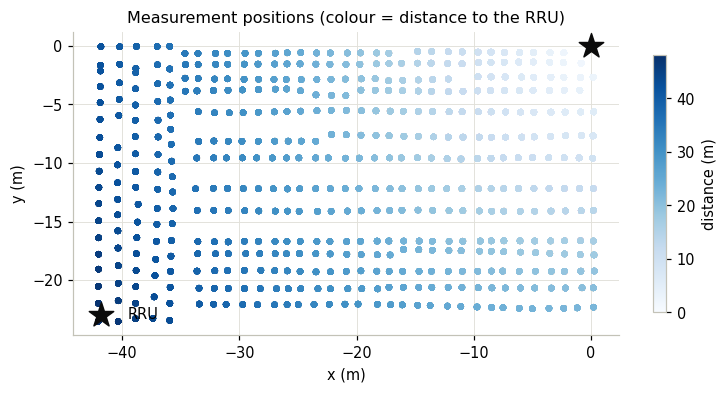

In [6]:
# Figure: measurement positions
dist_train = np.linalg.norm(xy_train, axis=1)
fig, ax = plt.subplots(figsize=(8, 3.8))
sc = ax.scatter(xy_train[:, 0], xy_train[:, 1], c=dist_train, cmap='Blues', s=10, vmin=0)
ax.scatter(0, 0, marker='*', s=280, color='#0b0b0b', label='RRU')
ax.set(xlabel='x (m)', ylabel='y (m)', title='Measurement positions (colour = distance to the RRU)')
ax.set_aspect('equal')
plt.colorbar(sc, ax=ax, label='distance (m)', shrink=0.8)
ax.legend(loc='lower left')
plt.show()

## 2. Data pre-processing
The complex CSI $H_{a,k}$ (antenna $a$, subcarrier $k$) is turned into **three input formats** (the same as in the
LoS/NLoS notebook):

1. **Amplitude image** $|H_{a,k}|$, 4 neighbouring subcarriers averaged (1632 → 408), min-max normalized to [0, 1]
   with the **training** minimum and maximum: $x_{norm} = (x - x_{min}) / (x_{max} - x_{min})$. The phase is not used
   directly because it contains random receiver offsets. dB scaling and per-sample scaling are tested in 6.2.
   The absolute amplitude matters here: the received power falls with the distance to the RRU.
2. **Channel impulse response (CIR)** $|h_a[\tau]| = |\mathrm{IFFT}_k(H_{a,k})|$, first 128 taps (99.4 % of the
   energy), scaled by the training maximum. The delays of the paths depend on the geometry.
3. **46 physical features** (10 per antenna + 6 inter-antenna correlations): received power, frequency selectivity,
   Rician K-factor, kurtosis, strongest-tap delay and energy ratio, mean excess delay, RMS delay spread, first-path
   delay and power, and the correlation of |H| between antenna pairs.

**Targets.** For the networks the coordinates are standardized, $\tilde{x} = (x - \mu_x)/\sigma_x$ and
$\tilde{y} = (y - \mu_y)/\sigma_y$ with the training mean and standard deviation, so that both outputs have the same
scale; predictions are transformed back to metres. The ML models predict the coordinates in metres directly.

In [7]:
POOL = 4          # neighbouring subcarriers averaged together (1632 -> 408)
N_TAPS = 128      # CIR taps kept
PER_ANTENNA = ['power_dB', 'freq_std_dB', 'K_factor_dB', 'kurtosis', 'peak_tap', 'peak_ratio_dB',
               'mean_delay', 'rms_delay', 'first_path_tap', 'first_path_dB']
PHYS_NAMES = ([f'{n} (ant {a + 1})' for n in PER_ANTENNA for a in range(4)] +
              [f'corr (ant {i + 1},{j + 1})' for i in range(4) for j in range(i + 1, 4)])
N_PHYS = len(PHYS_NAMES)


def physical_features(amp, cir):
    """46 hand-crafted features from |H| (N, 4, 1632) and |CIR| (N, 4, N_TAPS)."""
    eps = 1e-12
    p = amp ** 2
    mean_p = p.mean(-1)
    power_db = 10 * torch.log10(mean_p + eps)
    freq_std_db = (20 * torch.log10(amp + 1e-3)).std(-1)
    gamma = p.var(-1) / (mean_p ** 2 + eps)
    s = torch.sqrt(torch.clamp(1 - gamma, min=0))
    k_db = 10 * torch.log10(s / (1 - s + 1e-6) + 1e-3)
    centred = amp - amp.mean(-1, keepdim=True)
    kurtosis = (centred ** 4).mean(-1) / ((centred ** 2).mean(-1) ** 2 + eps)
    pdp = cir ** 2                                                    # power delay profile
    total = pdp.sum(-1) + eps
    tau = torch.arange(pdp.shape[-1], dtype=pdp.dtype)
    peak, peak_tap = pdp.max(-1)
    mean_delay = (pdp * tau).sum(-1) / total
    rms_delay = torch.sqrt((pdp * (tau - mean_delay[..., None]) ** 2).sum(-1) / total)
    first_tap = (pdp >= 0.1 * peak[..., None]).float().argmax(-1)    # first tap within 10 dB of the peak
    first_db = 10 * torch.log10((pdp.gather(-1, first_tap[..., None])[..., 0] + eps) / (peak + eps))
    unit = centred / (centred.norm(dim=-1, keepdim=True) + eps)
    corr = unit @ unit.transpose(1, 2)
    i, j = torch.triu_indices(4, 4, 1)
    feats = torch.cat([power_db, freq_std_db, k_db, kurtosis, peak_tap.float(), 10 * torch.log10(peak / total + eps),
                       mean_delay, rms_delay, first_tap.float(), first_db, corr[:, i, j]], dim=1)
    return torch.nan_to_num(feats)


def extract_features(H, chunk=1000):
    """complex CSI (N, 4, 1632) -> amplitude (N, 4, 408), |CIR| (N, 4, 128), physical features (N, 46)."""
    amp, cir, phys = [], [], []
    for Hc in torch.split(H, chunk):
        a = Hc.abs()
        h = torch.fft.ifft(Hc, dim=-1).abs()[..., :N_TAPS]
        amp.append(F.avg_pool1d(a, POOL))
        cir.append(h)
        phys.append(physical_features(a, h))
    return torch.cat(amp), torch.cat(cir), torch.cat(phys)


def to_db(amp):
    return 20 * torch.log10(1 + amp)


class Normalizer:
    """Scaling to [0, 1] with statistics of the training set only (no information from the validation set)."""
    def __init__(self, amp, cir):
        self.amp_min, self.amp_max = amp.min().item(), amp.max().item()
        db = to_db(amp)
        self.db_min, self.db_max = db.min().item(), db.max().item()
        self.cir_max = cir.max().item()

    def __call__(self, amp, cir):
        return {'amp': (amp - self.amp_min) / (self.amp_max - self.amp_min),
                'amp_db': (to_db(amp) - self.db_min) / (self.db_max - self.db_min),
                'amp_sample': amp / (amp.amax(dim=(1, 2), keepdim=True) + 1e-12),
                'cir': cir / self.cir_max}


def preprocess(H):
    """complex CSI -> all model inputs (normalized with the training statistics)."""
    amp, cir, phys = extract_features(H)
    return {**norm(amp, cir), 'phys': phys.numpy()}

In [8]:
t0 = time.time()
amp_raw, cir_raw, phys_raw = extract_features(train_CSI)
norm = Normalizer(amp_raw, cir_raw)                              # statistics of the training set only
train_in = {**norm(amp_raw, cir_raw), 'phys': phys_raw.numpy()}
amp_raw_v, cir_raw_v, phys_raw_v = extract_features(valid_CSI)
valid_in = {**norm(amp_raw_v, cir_raw_v), 'phys': phys_raw_v.numpy()}
RAW = {'amp': torch.cat([amp_raw, amp_raw_v]), 'cir': torch.cat([cir_raw, cir_raw_v])}   # unscaled, for Section 9
del amp_raw, cir_raw, phys_raw, amp_raw_v, cir_raw_v, phys_raw_v
print(f'pre-processing of 20,000 samples: {time.time() - t0:.1f} s')
for k, v in train_in.items():
    print(f'{k:11s} {str(tuple(v.shape)):16s} range [{v.min():8.3f}, {v.max():8.3f}]')

XY_MEAN, XY_STD = xy_train.mean(0), xy_train.std(0)
print('target mean (m):', XY_MEAN.round(2), '| target std (m):', XY_STD.round(2))

pre-processing of 20,000 samples: 2.1 s
amp         (15000, 4, 408)  range [   0.000,    1.000]
amp_db      (15000, 4, 408)  range [   0.000,    1.000]
amp_sample  (15000, 4, 408)  range [   0.004,    1.000]
cir         (15000, 4, 128)  range [   0.000,    1.000]
phys        (15000, 46)      range [ -30.000,  123.000]
target mean (m): [-20.8  -11.16] | target std (m): [12.48  7.16]


**Check: the pre-processing uses the training data only.** The scaling statistics and the target mean / standard
deviation come from `train_dl.pt`; the validation data are transformed with them, so the scaled training data lie
exactly in [0, 1] while the validation data may fall slightly outside. The PCA and standardization steps of the ML
models are fitted inside each pipeline on the training rows only; in Section 9 everything is recomputed from the seen
positions only.

In [9]:
n_tr = len(xy_train)
assert norm.amp_min == RAW['amp'][:n_tr].min().item() and norm.amp_max == RAW['amp'][:n_tr].max().item()
assert norm.cir_max == RAW['cir'][:n_tr].max().item()
assert np.allclose(XY_MEAN, xy_train.mean(0)) and np.allclose(XY_STD, xy_train.std(0))
for name, inputs in [('train', train_in), ('valid', valid_in)]:
    print(f"{name}: scaled |H| in [{inputs['amp'].min():.4f}, {inputs['amp'].max():.4f}] | "
          f"scaled CIR in [{inputs['cir'].min():.4f}, {inputs['cir'].max():.4f}]")
print('all scaling statistics are computed from the 15,000 training samples only: OK')

train: scaled |H| in [0.0000, 1.0000] | scaled CIR in [0.0000, 1.0000]
valid: scaled |H| in [0.0000, 0.8550] | scaled CIR in [0.0000, 0.9812]
all scaling statistics are computed from the 15,000 training samples only: OK


The complex training CSI is kept on the GPU (if there is one) for the noise / packet-loss augmentation in Section 8.

In [10]:
train_CSI = train_CSI.to(device)
train_gpu = {k: train_in[k].to(device) for k in ['amp', 'amp_db', 'amp_sample', 'cir']}
valid_gpu = {k: valid_in[k].to(device) for k in ['amp', 'amp_db', 'amp_sample', 'cir']}
mean_t, std_t = torch.tensor(XY_MEAN, dtype=torch.float32, device=device), torch.tensor(XY_STD, dtype=torch.float32, device=device)
target_train = (torch.tensor(xy_train, dtype=torch.float32, device=device) - mean_t) / std_t

### How does the CSI depend on the position?
**Left:** the received power (mean of the 4 antennas) against $\log_{10}$ of the distance, with the least-squares
log-distance path-loss model $P = P_0 - 10\,n\log_{10} d$. **Middle:** the delay of the strongest CIR tap.
**Right:** the first two principal components of the amplitude image, coloured by the x coordinate.

path-loss exponent n = 1.55, R^2 = 0.260
distance estimated from the power alone (linear regression on log-distance): mean |error| 7.93 m, always the mean distance: 9.12 m (distance range 1.7-48.2 m)


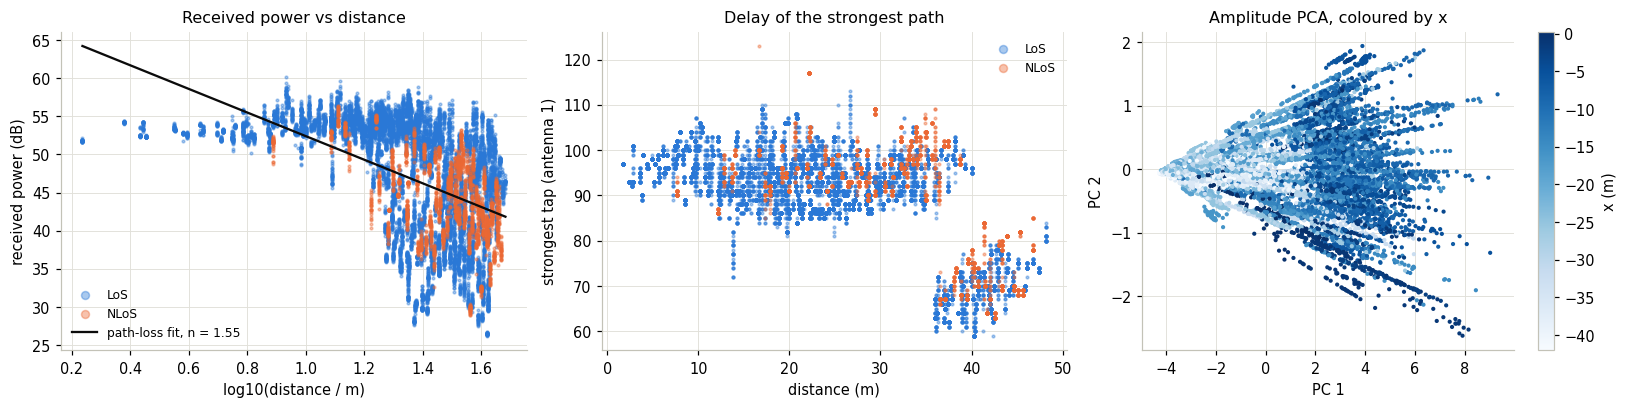

In [11]:
# Figure: CSI vs position
power = pd.DataFrame(train_in['phys'], columns=PHYS_NAMES)[[f'power_dB (ant {a + 1})' for a in range(4)]].mean(1).values
power_v = pd.DataFrame(valid_in['phys'], columns=PHYS_NAMES)[[f'power_dB (ant {a + 1})' for a in range(4)]].mean(1).values
log_d = np.log10(dist_train)
path_loss = LinearRegression().fit(log_d[:, None], power)
exponent = -path_loss.coef_[0] / 10
inverse = LinearRegression().fit(power[:, None], log_d)          # linear regression: power -> log-distance
d_hat = 10 ** inverse.predict(power_v[:, None])
dist_valid = np.linalg.norm(xy_valid, axis=1)
print(f'path-loss exponent n = {exponent:.2f}, R^2 = {path_loss.score(log_d[:, None], power):.3f}')
print(f'distance estimated from the power alone (linear regression on log-distance): mean |error| '
      f'{np.abs(d_hat - dist_valid).mean():.2f} m, always the mean distance: {np.abs(dist_train.mean() - dist_valid).mean():.2f} m '
      f'(distance range {dist_valid.min():.1f}-{dist_valid.max():.1f} m)')

peak_tap = pd.DataFrame(train_in['phys'], columns=PHYS_NAMES)['peak_tap (ant 1)'].values
pc = PCA(2, random_state=SEED).fit_transform(train_in['amp'].flatten(1).numpy())
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for c, name in enumerate(CLASSES):
    m = los_train == c
    axes[0].scatter(log_d[m], power[m], s=3, alpha=0.4, color=COLORS[name], label=name)
    axes[1].scatter(dist_train[m], peak_tap[m], s=3, alpha=0.4, color=COLORS[name], label=name)
grid = np.linspace(log_d.min(), log_d.max(), 50)
axes[0].plot(grid, path_loss.predict(grid[:, None]), color='#0b0b0b', lw=1.5, label=f'path-loss fit, n = {exponent:.2f}')
axes[0].set(xlabel='log10(distance / m)', ylabel='received power (dB)', title='Received power vs distance')
axes[1].set(xlabel='distance (m)', ylabel='strongest tap (antenna 1)', title='Delay of the strongest path')
sc = axes[2].scatter(pc[:, 0], pc[:, 1], c=xy_train[:, 0], cmap='Blues', s=3)
plt.colorbar(sc, ax=axes[2], label='x (m)')
axes[2].set(xlabel='PC 1', ylabel='PC 2', title='Amplitude PCA, coloured by x')
axes[0].legend(fontsize=8, markerscale=3)
axes[1].legend(fontsize=8, markerscale=3)
plt.tight_layout()
plt.show()

# Part A — Machine-learning methods
## 3. Input formats for ML and the five ML models
Four feature sets, as in the LoS/NLoS notebook: **Amplitude (PCA)** (first 100 principal components of the
flattened 4 × 408 amplitude image), **CIR (PCA)** (100 components of the flattened 4 × 128 CIR), **Physical** (46
standardized features) and **Physical + CIR (PCA)** (46 features + 50 CIR components, standardized).

| Model | Prediction function | Output |
|---|---|---|
| Linear Regression (Ridge) | $\hat{\mathbf{p}} = W^\top x + b$, L2 penalty $\alpha\lVert W\rVert^2$ (identity activation) | $(\hat x, \hat y)$ |
| KNN (fingerprinting) | mean position of the $k$ training fingerprints closest to the CSI (Euclidean) | $(\hat x, \hat y)$ |
| SVR (RBF kernel) | $f(x) = \sum_i (\alpha_i - \alpha_i^*) \exp(-\gamma\lVert x - x_i\rVert^2) + b$, ε-insensitive loss, one model per coordinate | $(\hat x, \hat y)$ |
| Random Forest | mean prediction of many regression trees (bagging, random features) | $(\hat x, \hat y)$ |
| Gradient Boosting | sum of shallow trees fitted one after the other to the residual, one model per coordinate | $(\hat x, \hat y)$ |

Ridge and SVR use standardized inputs; KNN uses the raw PCA components (they keep the Euclidean distance between
fingerprints); trees need no scaling. The metric is the Euclidean **position error** $\lVert \hat{\mathbf p} - \mathbf p\rVert$ in metres.

In [12]:
FEATURE_SETS = ['Amplitude (PCA)', 'CIR (PCA)', 'Physical', 'Physical + CIR (PCA)']


def ml_matrix(inputs, feature_set):
    """The 2-D input matrix of an ML pipeline."""
    if feature_set == 'Amplitude (PCA)':
        return inputs['amp'].flatten(1).numpy()
    if feature_set == 'CIR (PCA)':
        return inputs['cir'].flatten(1).numpy()
    if feature_set == 'Physical':
        return inputs['phys']
    return np.hstack([inputs['phys'], inputs['cir'].flatten(1).numpy()])


def ml_pipeline(feature_set, model, n_pca=100, scale=True):
    if feature_set == 'Physical':
        steps = [StandardScaler()]
    elif feature_set == 'Physical + CIR (PCA)':
        steps = [ColumnTransformer([('phys', StandardScaler(), slice(0, N_PHYS)),
                                    ('cir', make_pipeline(PCA(50, random_state=SEED), StandardScaler()),
                                     slice(N_PHYS, None))])]
    else:
        steps = [PCA(n_pca, random_state=SEED)] + ([StandardScaler()] if scale else [])
    return make_pipeline(*steps, model)


ML_MODELS = {'Linear Regression': (lambda: Ridge(alpha=1.0), True),
             'KNN': (lambda: KNeighborsRegressor(n_neighbors=5), False),
             'Random Forest': (lambda: RandomForestRegressor(n_estimators=100, max_features='sqrt', n_jobs=-1,
                                                             random_state=SEED), False),
             'Gradient Boosting': (lambda: MultiOutputRegressor(HistGradientBoostingRegressor(random_state=SEED)), False)}

Helper functions: position-error metrics, training / inference time and model size (bytes of the pickled pipeline).

In [13]:
def position_errors(pred, true):
    return np.linalg.norm(np.asarray(pred) - np.asarray(true), axis=1)


def pos_metrics(pred, true):
    e = position_errors(pred, true)
    return {'mean_m': e.mean(), 'median_m': np.median(e), 'RMSE_m': np.sqrt(np.mean(e ** 2)),
            'p90_m': np.percentile(e, 90), 'within_1m': np.mean(e <= 1)}


def fit_ml(model, X_tr, y_tr, X_te, y_te):
    start = time.time()
    model.fit(X_tr, y_tr)
    train_s = time.time() - start
    start = time.time()
    pred = model.predict(X_te)
    infer_s = time.time() - start
    return ({**pos_metrics(pred, y_te), 'train_s': train_s, 'infer_ms': 1000 * infer_s / len(X_te),
             'size_MB': len(pickle.dumps(model)) / 1e6}, pred)

### 3.1 Which input format is best for ML?
Linear Regression, KNN (k = 5), Random Forest and Gradient Boosting with default settings on the four feature sets
(SVR is slow — it is tuned on one feature set in 4.3).

In [14]:
X_train = {fs: ml_matrix(train_in, fs) for fs in FEATURE_SETS}
X_valid = {fs: ml_matrix(valid_in, fs) for fs in FEATURE_SETS}
rows = []
for fs in FEATURE_SETS:
    for name, (make, scale) in ML_MODELS.items():
        r, _ = fit_ml(ml_pipeline(fs, make(), scale=scale), X_train[fs], xy_train, X_valid[fs], xy_valid)
        rows.append({'feature set': fs, 'model': name, **r})
feature_table = pd.DataFrame(rows)
feature_table.round(4)

,feature set,model,mean_m,median_m,RMSE_m,p90_m,within_1m,train_s,infer_ms,size_MB
0,Amplitude (PCA),Linear Regression,8.3132,7.8316,9.4381,13.9836,0.0136,1.1020,0.0037,0.6652
1,Amplitude (PCA),KNN,0.0344,0.0000,0.7203,0.0000,0.9958,1.0003,0.0413,6.9018
2,Amplitude (PCA),Random Forest,0.5761,0.3039,1.1099,1.2967,0.8578,2.0281,0.0101,18.7843
3,Amplitude (PCA),Gradient Boosting,1.2136,0.8751,1.7738,2.4391,0.5724,2.1658,0.0068,1.7924
4,CIR (PCA),Linear Regression,8.0803,7.5881,9.1857,13.5095,0.0124,0.0918,0.0000,0.2127
5,CIR (PCA),KNN,1.4742,0.0000,3.5826,5.3634,0.7310,0.1070,0.0186,6.4494
6,CIR (PCA),Random Forest,2.2985,1.4082,3.4142,5.5564,0.3910,1.1585,0.0127,54.7619
7,CIR (PCA),Gradient Boosting,3.2139,2.4491,4.1910,6.7281,0.1360,1.2408,0.0050,1.3400
8,Physical,Linear Regression,6.4752,6.0420,7.2965,10.9757,0.0180,0.0126,0.0006,0.0024
9,Physical,KNN,0.8844,0.0000,2.4412,2.9360,0.7886,0.0091,0.0099,3.0022


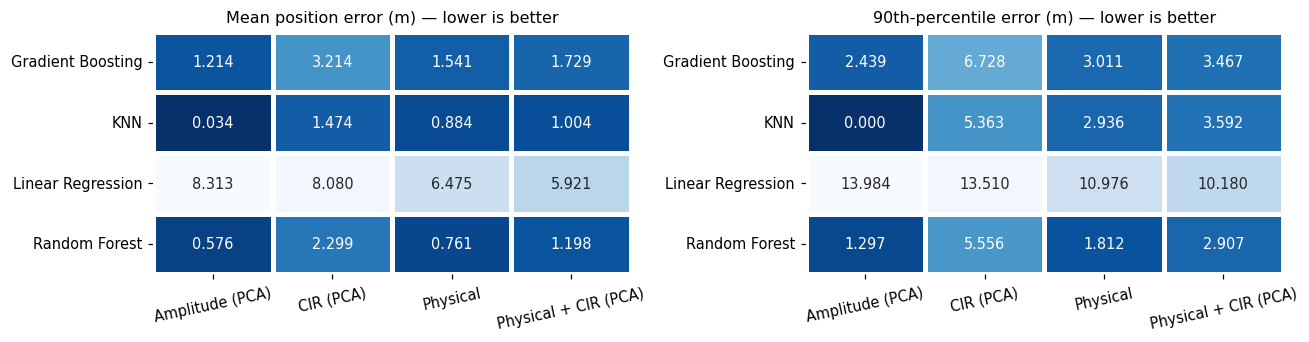

In [15]:
# Figure: ML feature-set comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
for ax, (metric, title) in zip(axes, [('mean_m', 'Mean position error (m)'), ('p90_m', '90th-percentile error (m)')]):
    sn.heatmap(feature_table.pivot(index='model', columns='feature set', values=metric)[FEATURE_SETS],
               annot=True, fmt='.3f', cmap='Blues_r', cbar=False, ax=ax, linewidths=2, linecolor='white')
    ax.set(title=title + ' — lower is better', xlabel='', ylabel='')
    ax.tick_params(axis='x', rotation=12)
plt.tight_layout()
plt.show()

## 4. Configurations of every ML model
Linear Regression, KNN and SVR are tuned on the PCA amplitude features (PCA fitted once with 400 components; the first
*n* columns give the *n*-component features). The tree ensembles use the PCA amplitude features too, which gave the
lowest error in 3.1.

In [16]:
pca400 = PCA(400, random_state=SEED).fit(X_train['Amplitude (PCA)'])
Z_train, Z_valid = pca400.transform(X_train['Amplitude (PCA)']), pca400.transform(X_valid['Amplitude (PCA)'])
print('variance kept by 10 / 50 / 100 / 400 components:',
      [round(float(pca400.explained_variance_ratio_[:n].sum()), 4) for n in [10, 50, 100, 400]])


def grid_row(model, X_tr, X_te, **config):
    r, _ = fit_ml(model, X_tr, xy_train, X_te, xy_valid)
    return {**config, **{k: r[k] for k in ['mean_m', 'median_m', 'p90_m', 'train_s', 'infer_ms']}}


def best_row(table):
    """Lowest mean error, then the fastest training."""
    return table.sort_values(['mean_m', 'train_s']).iloc[0]

variance kept by 10 / 50 / 100 / 400 components: [0.8987, 0.9771, 0.9933, 0.9993]


### 4.1 Linear Regression — number of PCA components × L2 penalty `alpha`
A second variant feeds degree-2 polynomial features of the physical features (46 → 1127 products) to the linear model.

In [17]:
rows = []
for n in [10, 50, 100, 200, 400]:
    for alpha in [0.01, 1, 100]:
        rows.append(grid_row(make_pipeline(StandardScaler(), Ridge(alpha=alpha)), Z_train[:, :n], Z_valid[:, :n],
                             input='Amplitude (PCA)', PCA=n, alpha=alpha))
for alpha in [0.1, 1, 10, 100]:
    model = make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False), StandardScaler(), Ridge(alpha=alpha))
    rows.append(grid_row(model, X_train['Physical'], X_valid['Physical'], input='Physical (poly-2)', PCA=0, alpha=alpha))
lr_grid = pd.DataFrame(rows)
lr_grid.sort_values('mean_m').head(8).round(4)

,input,PCA,alpha,mean_m,median_m,p90_m,train_s,infer_ms
15,Physical (poly-2),0,0.10,3.3243,2.8590,5.9645,0.7583,0.0243
16,Physical (poly-2),0,1.00,3.4156,2.9854,6.1581,0.6742,0.0232
17,Physical (poly-2),0,10.00,3.6576,3.2283,6.5639,0.7082,0.0225
18,Physical (poly-2),0,100.00,4.0331,3.6420,7.2057,0.7926,0.0208
13,Amplitude (PCA),400,1.00,5.5349,5.0260,10.0088,0.1769,0.0037
12,Amplitude (PCA),400,0.01,5.5349,5.0254,10.0085,0.1298,0.0034
14,Amplitude (PCA),400,100.00,5.5354,5.0268,10.0109,0.2124,0.0057
9,Amplitude (PCA),200,0.01,6.9281,6.4150,11.8867,0.1155,0.0002


### 4.2 KNN — number of neighbours `k` × neighbour weighting × number of PCA components

In [18]:
rows = []
for n in [20, 100]:
    for weights in ['uniform', 'distance']:
        for k in [1, 2, 3, 5, 10, 20]:
            rows.append(grid_row(KNeighborsRegressor(n_neighbors=k, weights=weights), Z_train[:, :n], Z_valid[:, :n],
                                 PCA=n, weights=weights, k=k))
knn_grid = pd.DataFrame(rows)
knn_grid.sort_values('mean_m').head(6).round(4)

,PCA,weights,k,mean_m,median_m,p90_m,train_s,infer_ms
12,100,uniform,1,0.0037,0.0,0.0,0.0050,0.0183
18,100,distance,1,0.0037,0.0,0.0,0.0036,0.0181
19,100,distance,2,0.0120,0.0,0.0,0.0021,0.0179
0,20,uniform,1,0.0130,0.0,0.0,0.0030,0.0150
6,20,distance,1,0.0130,0.0,0.0,0.0021,0.0075
13,100,uniform,2,0.0148,0.0,0.0,0.0031,0.0286


### 4.3 SVR (RBF kernel) — penalty `C` (50 standardized PCA components, ε = 0.1 m, one SVR per coordinate)

In [19]:
rows = []
for C in [1, 10, 100]:
    model = make_pipeline(StandardScaler(), MultiOutputRegressor(SVR(C=C, epsilon=0.1, gamma='scale')))
    rows.append(grid_row(model, Z_train[:, :50], Z_valid[:, :50], PCA=50, C=C))
svr_grid = pd.DataFrame(rows)
svr_grid.round(4)

,PCA,C,mean_m,median_m,p90_m,train_s,infer_ms
0,50,1,3.5392,1.5774,10.0847,26.2096,2.5608
1,50,10,1.8608,0.7094,5.6955,28.5531,2.9014
2,50,100,1.1952,0.5227,3.0984,78.8531,2.4773


### 4.4 Random Forest — number of trees × features tried per split (100 PCA components)

In [20]:
rows = []
for n_trees in [50, 150]:
    for max_features in ['sqrt', 0.33, 1.0]:
        model = RandomForestRegressor(n_estimators=n_trees, max_features=max_features, n_jobs=-1, random_state=SEED)
        rows.append(grid_row(model, Z_train[:, :100], Z_valid[:, :100], trees=n_trees, max_features=str(max_features)))
rf_grid = pd.DataFrame(rows)
rf_grid.round(4)

,trees,max_features,mean_m,median_m,p90_m,train_s,infer_ms
0,50,sqrt,0.6084,0.3320,1.4374,0.8500,0.0052
1,50,0.33,0.5197,0.2438,1.2204,2.8080,0.0147
2,50,1.0,0.4948,0.1526,1.1910,9.6387,0.0142
3,150,sqrt,0.5609,0.2925,1.2539,3.4775,0.0193
4,150,0.33,0.4759,0.2158,1.0343,7.7331,0.0104
5,150,1.0,0.4638,0.1448,1.0822,24.7016,0.0162


### 4.5 Gradient Boosting — learning rate × number of boosting iterations (100 PCA components)

In [21]:
rows = []
for lr in [0.05, 0.1, 0.3]:
    for n_iter in [100, 300]:
        model = MultiOutputRegressor(HistGradientBoostingRegressor(learning_rate=lr, max_iter=n_iter, random_state=SEED))
        rows.append(grid_row(model, Z_train[:, :100], Z_valid[:, :100], learning_rate=lr, iterations=n_iter))
gb_grid = pd.DataFrame(rows)
gb_grid.round(4)

,learning_rate,iterations,mean_m,median_m,p90_m,train_s,infer_ms
0,0.05,100,1.8212,1.3893,3.5156,2.4342,0.0104
1,0.05,300,1.0067,0.6858,2.0483,6.4791,0.0257
2,0.10,100,1.2254,0.8776,2.4343,2.4931,0.0119
3,0.10,300,0.9592,0.6833,1.8962,6.7596,0.0208
4,0.30,100,1.3219,0.9625,2.7092,1.7618,0.0069
5,0.30,300,1.2733,0.9399,2.6320,2.7497,0.0125


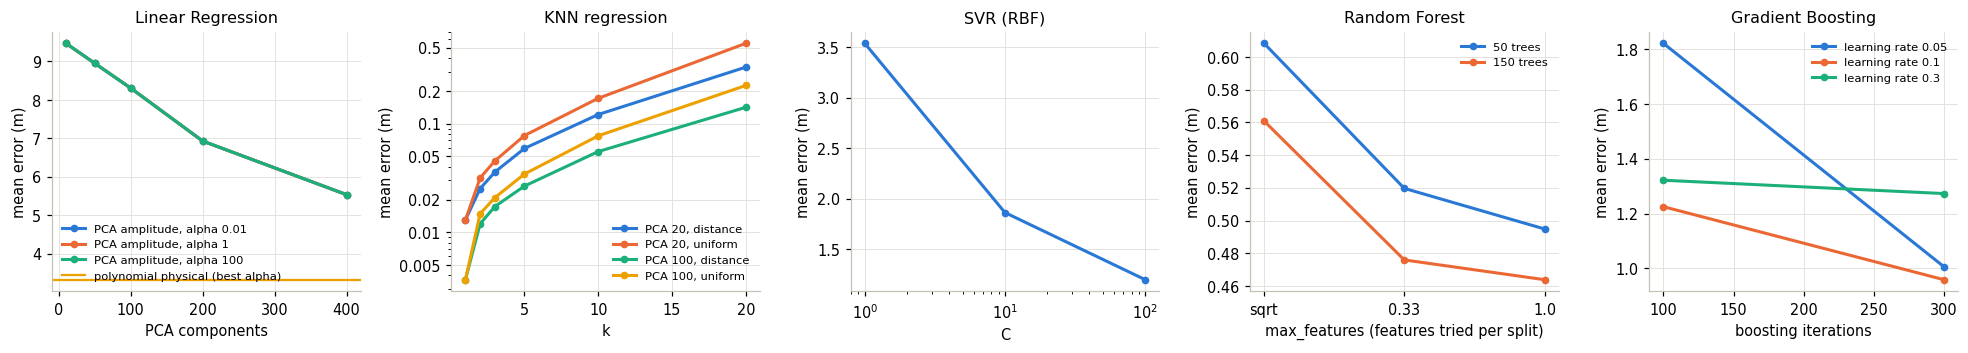

In [22]:
# Figure: ML configuration grids
fig, axes = plt.subplots(1, 5, figsize=(18, 3.3))
lin = lr_grid[lr_grid['input'] == 'Amplitude (PCA)']
for i, alpha in enumerate(sorted(lin['alpha'].unique())):
    r = lin[lin['alpha'] == alpha]
    axes[0].plot(r['PCA'], r['mean_m'], marker='o', ms=4, color=PALETTE[i], label=f'PCA amplitude, alpha {alpha:g}')
poly = lr_grid[lr_grid['input'] == 'Physical (poly-2)']
axes[0].axhline(poly['mean_m'].min(), color=PALETTE[3], lw=1.5, label='polynomial physical (best alpha)')
axes[0].set(xlabel='PCA components', ylabel='mean error (m)', title='Linear Regression')
axes[0].legend(fontsize=7.5)
for i, ((n, weights), r) in enumerate(knn_grid.groupby(['PCA', 'weights'])):
    axes[1].plot(r['k'], r['mean_m'], marker='o', ms=4, color=PALETTE[i], label=f'PCA {n}, {weights}')
axes[1].set(xlabel='k', ylabel='mean error (m)', title='KNN regression')
log_axis(axes[1], 'y')
axes[1].legend(fontsize=7.5)
axes[2].plot(svr_grid['C'], svr_grid['mean_m'], marker='o', ms=4, label='SVR')
axes[2].set(xscale='log', xlabel='C', ylabel='mean error (m)', title='SVR (RBF)')
for i, (n_trees, r) in enumerate(rf_grid.groupby('trees')):
    axes[3].plot(r['max_features'], r['mean_m'], marker='o', ms=4, color=PALETTE[i], label=f'{n_trees} trees')
axes[3].set(xlabel='max_features (features tried per split)', ylabel='mean error (m)', title='Random Forest')
axes[3].legend(fontsize=7.5)
for i, (lr, r) in enumerate(gb_grid.groupby('learning_rate')):
    axes[4].plot(r['iterations'], r['mean_m'], marker='o', ms=4, color=PALETTE[i], label=f'learning rate {lr:g}')
axes[4].set(xlabel='boosting iterations', ylabel='mean error (m)', title='Gradient Boosting')
axes[4].legend(fontsize=7.5)
plt.tight_layout()
plt.show()

### 4.6 Final ML models
The best configuration of every model is rebuilt as one complete pipeline (raw input → PCA / scaling → model) and
trained again, so that the reported training time, inference time and size include the pre-processing step.

In [23]:
best = {'Linear Regression': best_row(lr_grid), 'KNN': best_row(knn_grid), 'SVR (RBF)': best_row(svr_grid),
        'Random Forest': best_row(rf_grid), 'Gradient Boosting': best_row(gb_grid)}
for name, row in best.items():
    print(f'{name:18s}', {k: v for k, v in row.items() if k not in ['mean_m', 'median_m', 'p90_m', 'train_s', 'infer_ms']})

b = best['Linear Regression']
if b['input'] == 'Physical (poly-2)':
    lr_final = ('Physical', make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False), StandardScaler(),
                                          Ridge(alpha=b['alpha'])))
else:
    lr_final = ('Amplitude (PCA)', ml_pipeline('Amplitude (PCA)', Ridge(alpha=b['alpha']), int(b['PCA'])))
b_knn, b_rf, b_gb = best['KNN'], best['Random Forest'], best['Gradient Boosting']
rf_features = b_rf['max_features'] if b_rf['max_features'] == 'sqrt' else float(b_rf['max_features'])
final_ml = {
    'Linear Regression': lr_final,
    'KNN': ('Amplitude (PCA)', ml_pipeline('Amplitude (PCA)', KNeighborsRegressor(int(b_knn['k']), weights=b_knn['weights']),
                                           int(b_knn['PCA']), scale=False)),
    'SVR (RBF)': ('Amplitude (PCA)', ml_pipeline('Amplitude (PCA)', MultiOutputRegressor(
        SVR(C=best['SVR (RBF)']['C'], epsilon=0.1, gamma='scale')), 50)),
    'Random Forest': ('Amplitude (PCA)', ml_pipeline('Amplitude (PCA)', RandomForestRegressor(
        n_estimators=int(b_rf['trees']), max_features=rf_features, n_jobs=-1, random_state=SEED), 100, scale=False)),
    'Gradient Boosting': ('Amplitude (PCA)', ml_pipeline('Amplitude (PCA)', MultiOutputRegressor(HistGradientBoostingRegressor(
        learning_rate=b_gb['learning_rate'], max_iter=int(b_gb['iterations']), random_state=SEED)), 100, scale=False))}

Linear Regression  {'input': 'Physical (poly-2)', 'PCA': np.int64(0), 'alpha': np.float64(0.1)}
KNN                {'PCA': np.int64(100), 'weights': 'uniform', 'k': np.int64(1)}
SVR (RBF)          {'PCA': 50.0, 'C': 100.0}
Random Forest      {'trees': np.int64(150), 'max_features': '1.0'}
Gradient Boosting  {'learning_rate': 0.1, 'iterations': 300.0}


Efficiency: besides the batch inference time on the 5000 validation samples, the **latency for one sample** is
measured (median of 100 calls, one CPU thread for PyTorch): a vehicle is positioned one CSI report at a time.

In [24]:
def cpu_latency_ms(fn, runs=100):
    threads = torch.get_num_threads()
    torch.set_num_threads(1)
    for _ in range(10):
        fn()
    times = []
    for _ in range(runs):
        start = time.perf_counter()
        fn()
        times.append(time.perf_counter() - start)
    torch.set_num_threads(threads)
    return 1000 * float(np.median(times))


def ml_latency(model, X):
    est = model[-1]
    n_jobs = getattr(est, 'n_jobs', None)
    if hasattr(est, 'n_jobs'):
        est.n_jobs = 1                    # no thread pool for a single sample
    latency = cpu_latency_ms(lambda: model.predict(X[:1]), runs=30)
    if hasattr(est, 'n_jobs'):
        est.n_jobs = n_jobs
    return latency


ml_rows, ml_pred = [], {}
for name, (fs, model) in final_ml.items():
    r, ml_pred[name] = fit_ml(model, X_train[fs], xy_train, X_valid[fs], xy_valid)
    ml_rows.append({'model': name, 'type': 'ML', 'input': fs, **r, 'params': np.nan,
                    'cpu_latency_ms': ml_latency(model, X_valid[fs])})
ml_table = pd.DataFrame(ml_rows).set_index('model')
ml_table.round(4)

,type,input,mean_m,median_m,RMSE_m,p90_m,within_1m,train_s,infer_ms,size_MB,params,cpu_latency_ms
model,,,,,,,,,,,,
Linear Regression,ML,Physical,3.3243,2.8590,4.1229,5.9645,0.0928,0.8053,0.0176,0.0385,NaN,0.9000
KNN,ML,Amplitude (PCA),0.0037,0.0000,0.2363,0.0000,0.9996,1.3299,0.0431,6.9018,NaN,1.2886
SVR (RBF),ML,Amplitude (PCA),1.1982,0.5266,2.1662,3.0957,0.6890,101.4899,3.4837,9.6665,NaN,4.8614
Random Forest,ML,Amplitude (PCA),0.4686,0.1486,1.2095,1.0971,0.8878,31.6522,0.0230,25.4576,NaN,8.9042
Gradient Boosting,ML,Amplitude (PCA),0.9513,0.6748,1.4312,1.8833,0.6894,7.5730,0.0263,3.2195,NaN,29.0704


**Why is KNN almost perfect here?** Every validation sample was measured at one of the 476 positions that are also
in the training set, and samples of the same position have nearly identical fingerprints. A 1-NN model therefore
returns the exact training coordinates — it solves a look-up problem, not an interpolation problem (see Section 9).

In [25]:
print('share of validation samples whose 1-NN prediction is exactly a training position:',
      np.mean(position_errors(ml_pred['KNN'], xy_valid) < 1e-6) if best['KNN']['k'] == 1 else 'k > 1')
best_ml = ml_table['mean_m'].idxmin()
print('best ML model:', best_ml)

share of validation samples whose 1-NN prediction is exactly a training position: 0.9996
best ML model: KNN


# Part B — Artificial neural networks
## 5. ANN design
**Inputs.** The normalized amplitude image (4 × 408, the 4 antennas are the 4 input channels of the 1-D
convolutions), the CIR (4 × 128), or both (fusion network). The architectures are the same as in the LoS/NLoS notebook:

| Network | Structure |
|---|---|
| MLP | flatten (1632) → 512 → 256 → output; dropout 0.2 |
| CNN-1D | 3 × [Conv1d (k = 7, 5, 3) → BatchNorm → activation → pooling], 32/64/128 channels → FC 128 → output |
| CNN-2D | the CSI as a 1-channel image; kernels (3×7), (3×5) and (4×3) — the last one mixes all 4 antennas |
| ResNet-1D | stem conv + 4 residual blocks (two 3-tap convolutions + skip connection), global average pooling |
| CNN-BiGRU | 2 conv blocks shorten the sequence to 102 steps, a bidirectional GRU (64 units) reads it along frequency |
| Transformer | patches of 8 subcarriers × 4 antennas → 51 tokens of size 64, 2 self-attention layers (4 heads) |
| CIR-CNN | the CNN-1D applied to the CIR |
| Fusion CNN | one convolution branch for |H| and one for the CIR; features concatenated before the FC head |

**Activation functions.** ReLU in the hidden layers (LeakyReLU, ELU, GELU, Tanh and Sigmoid compared in 6.2).

**Output.** 2 neurons with **linear (identity) activation** that predict the standardized $(\tilde x, \tilde y)$;
loss = mean squared error (MSE). Alternatives compared in 6.2: a bounded output (sigmoid scaled to the area of the
measurement positions), **classification** over the 476 reference positions (softmax; prediction = coordinates of
the most likely position, or the probability-weighted mean of all positions) and the losses L1, Huber and the
Euclidean distance itself.

**Training.** Adam, learning rate 1e-3 with cosine decay over `MAX_EPOCHS` epochs, batch size 64. **Early stopping**
monitors the validation mean position error after every epoch, stops after `PATIENCE` epochs without improvement
and restores the best checkpoint.

In [26]:
def conv_block(c_in, c_out, k, act, pool):
    return [nn.Conv1d(c_in, c_out, k, padding=k // 2), nn.BatchNorm1d(c_out), act(), pool]


def make_mlp(n_out, n_in=4 * 408, act=nn.ReLU, hidden=(512, 256), dropout=0.2):
    layers, prev = [nn.Flatten()], n_in
    for h in hidden:
        layers += [nn.Linear(prev, h), act(), nn.Dropout(dropout)]
        prev = h
    return nn.Sequential(*layers, nn.Linear(prev, n_out))


def make_cnn1d(n_out, c_in=4, act=nn.ReLU, channels=(32, 64, 128), dropout=0.2):
    c1, c2, c3 = channels
    return nn.Sequential(*conv_block(c_in, c1, 7, act, nn.MaxPool1d(2)),
                         *conv_block(c1, c2, 5, act, nn.MaxPool1d(2)),
                         *conv_block(c2, c3, 3, act, nn.AdaptiveAvgPool1d(8)),
                         nn.Flatten(), nn.Linear(c3 * 8, 128), act(), nn.Dropout(dropout), nn.Linear(128, n_out))


class CNN2D(nn.Module):
    def __init__(self, n_out, act=nn.ReLU):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 16, (3, 7), padding=(1, 3)), nn.BatchNorm2d(16), act(), nn.MaxPool2d((1, 2)),
            nn.Conv2d(16, 32, (3, 5), padding=(1, 2)), nn.BatchNorm2d(32), act(), nn.MaxPool2d((1, 2)),
            nn.Conv2d(32, 64, (4, 3), padding=(0, 1)), nn.BatchNorm2d(64), act(), nn.AdaptiveAvgPool2d((1, 8)),
            nn.Flatten(), nn.Linear(64 * 8, 128), act(), nn.Dropout(0.2), nn.Linear(128, n_out))

    def forward(self, x):
        return self.net(x.unsqueeze(1))


class ResBlock1D(nn.Module):
    def __init__(self, c_in, c_out, stride):
        super().__init__()
        self.conv1, self.bn1 = nn.Conv1d(c_in, c_out, 3, stride, 1, bias=False), nn.BatchNorm1d(c_out)
        self.conv2, self.bn2 = nn.Conv1d(c_out, c_out, 3, 1, 1, bias=False), nn.BatchNorm1d(c_out)
        self.skip = (nn.Identity() if c_in == c_out and stride == 1 else
                     nn.Sequential(nn.Conv1d(c_in, c_out, 1, stride, bias=False), nn.BatchNorm1d(c_out)))

    def forward(self, x):
        return F.relu(self.bn2(self.conv2(F.relu(self.bn1(self.conv1(x))))) + self.skip(x))


class ResNet1D(nn.Module):
    def __init__(self, n_out, c_in=4):
        super().__init__()
        self.net = nn.Sequential(nn.Conv1d(c_in, 32, 7, 2, 3, bias=False), nn.BatchNorm1d(32), nn.ReLU(),
                                 ResBlock1D(32, 32, 1), ResBlock1D(32, 64, 2), ResBlock1D(64, 128, 2),
                                 ResBlock1D(128, 128, 2), nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Linear(128, n_out))

    def forward(self, x):
        return self.net(x)


class CNNBiGRU(nn.Module):
    def __init__(self, n_out, c_in=4, hidden=64):
        super().__init__()
        self.conv = nn.Sequential(*conv_block(c_in, 32, 7, nn.ReLU, nn.MaxPool1d(2)),
                                  *conv_block(32, 64, 5, nn.ReLU, nn.MaxPool1d(2)))
        self.gru = nn.GRU(64, hidden, batch_first=True, bidirectional=True)
        self.head = nn.Linear(2 * hidden, n_out)

    def forward(self, x):
        out, _ = self.gru(self.conv(x).transpose(1, 2))
        return self.head(out.mean(1))


class TransformerNet(nn.Module):
    def __init__(self, n_out, c_in=4, length=408, patch=8, d_model=64):
        super().__init__()
        self.embed = nn.Conv1d(c_in, d_model, patch, stride=patch)
        self.pos = nn.Parameter(torch.zeros(1, length // patch, d_model))
        layer = nn.TransformerEncoderLayer(d_model, nhead=4, dim_feedforward=128, dropout=0.1, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=2, enable_nested_tensor=False)
        self.head = nn.Linear(d_model, n_out)

    def forward(self, x):
        return self.head(self.encoder(self.embed(x).transpose(1, 2) + self.pos).mean(1))


class FusionCNN(nn.Module):
    def __init__(self, n_out):
        super().__init__()
        self.amp = nn.Sequential(*conv_block(4, 32, 7, nn.ReLU, nn.MaxPool1d(2)), *conv_block(32, 64, 5, nn.ReLU, nn.MaxPool1d(2)),
                                 *conv_block(64, 64, 3, nn.ReLU, nn.AdaptiveAvgPool1d(8)), nn.Flatten())
        self.cir = nn.Sequential(*conv_block(4, 32, 5, nn.ReLU, nn.MaxPool1d(2)),
                                 *conv_block(32, 64, 3, nn.ReLU, nn.AdaptiveAvgPool1d(8)), nn.Flatten())
        self.head = nn.Sequential(nn.Linear(2 * 64 * 8, 128), nn.ReLU(), nn.Dropout(0.2), nn.Linear(128, n_out))

    def forward(self, amp, cir):
        return self.head(torch.cat([self.amp(amp), self.cir(cir)], dim=1))


class BoundedOutput(nn.Module):
    """Sigmoid output scaled to the bounding box of the training positions (in standardized units)."""
    def __init__(self, low, high):
        super().__init__()
        self.register_buffer('low', low)
        self.register_buffer('high', high)

    def forward(self, z):
        return self.low + (self.high - self.low) * torch.sigmoid(z)


ARCHS = {'MLP': (('amp',), lambda n_out: make_mlp(n_out)),
         'CNN-1D': (('amp',), lambda n_out: make_cnn1d(n_out)),
         'CNN-2D': (('amp',), lambda n_out: CNN2D(n_out)),
         'ResNet-1D': (('amp',), lambda n_out: ResNet1D(n_out)),
         'CNN-BiGRU': (('amp',), lambda n_out: CNNBiGRU(n_out)),
         'Transformer': (('amp',), lambda n_out: TransformerNet(n_out)),
         'CIR-CNN': (('cir',), lambda n_out: make_cnn1d(n_out)),
         'Fusion CNN': (('amp', 'cir'), lambda n_out: FusionCNN(n_out))}

### Training and evaluation functions
`train_net` is generic: it receives the loss function, so the same loop trains regression, classification and
multi-task networks. `decode` turns the network output into coordinates in metres.

In [27]:
def sync():
    if device.type == 'cuda':
        torch.cuda.synchronize()


def make_optimizer(name, params, lr):
    if name == 'Adam':
        return torch.optim.Adam(params, lr=lr)
    if name == 'AdamW':
        return torch.optim.AdamW(params, lr=lr, weight_decay=1e-2)
    if name == 'SGD':
        return torch.optim.SGD(params, lr=lr, momentum=0.9, nesterov=True)
    return torch.optim.RMSprop(params, lr=lr)


@torch.no_grad()
def net_output(model, inputs, batch_size=1000):
    model.eval()
    return torch.cat([model(*(x[i:i + batch_size] for x in inputs)) for i in range(0, len(inputs[0]), batch_size)])


def decode(out, mode='regression', class_xy=None):
    """Network output -> coordinates in metres (numpy)."""
    if mode == 'regression':
        xy = out[:, :2] * std_t + mean_t
    elif mode == 'class (argmax)':
        xy = class_xy[out.argmax(1)]
    else:                                                   # 'class (expected position)'
        xy = out.softmax(1) @ class_xy
    return xy.cpu().numpy().astype(np.float64)


def predict_xy(model, inputs, mode='regression', class_xy=None):
    return decode(net_output(model, inputs), mode, class_xy)


def train_net(model, inputs, target, loss_fn, val_fn, max_epochs=MAX_EPOCHS, patience=PATIENCE, lr=1e-3, batch_size=64,
              optimizer='Adam', transform=None, verbose=False):
    """Mini-batch training with cosine learning-rate decay over `max_epochs` and early stopping: `val_fn(model)` gives
    the validation mean error (m) after every epoch; training stops after `patience` epochs without improvement and
    the best checkpoint is restored. Returns the history per epoch (history.attrs['best_epoch']) and the training time.
    `transform` maps a raw training batch to the network input (used for data augmentation)."""
    model.to(device)
    opt = make_optimizer(optimizer, model.parameters(), lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max_epochs)
    history, train_time = [], 0.0
    best_err, best_epoch, best_state = np.inf, 0, None
    for epoch in range(max_epochs):
        model.train()
        sync()
        start = time.time()
        perm = torch.randperm(len(target), device=device)
        total = torch.zeros((), device=device)
        for i in range(0, len(perm), batch_size):
            idx = perm[i:i + batch_size]
            if len(idx) < 2:
                continue
            xb = tuple(x[idx] for x in inputs)
            if transform is not None:
                xb = transform(*xb)
            loss = loss_fn(model(*xb), target[idx])
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            total += loss.detach() * len(idx)
        scheduler.step()
        sync()
        train_time += time.time() - start
        record = {'epoch': epoch + 1, 'train_loss': total.item() / len(perm), 'val_error_m': val_fn(model)}
        history.append(record)
        if verbose:
            print('  epoch %2d | train loss %.5f | validation mean error %.3f m' % tuple(record.values()))
        if record['val_error_m'] < best_err:
            best_err, best_epoch = record['val_error_m'], epoch + 1
            best_state = copy.deepcopy(model.state_dict())
        elif epoch + 1 - best_epoch >= patience:
            break
    model.load_state_dict(best_state)                 # best validation checkpoint
    history = pd.DataFrame(history)
    history.attrs['best_epoch'] = best_epoch
    if verbose:
        print(f'  early stopping after {len(history)} epochs, best checkpoint: epoch {best_epoch}')
    return history, train_time


def val_error(inputs, true_xy, mode='regression', class_xy=None):
    return lambda model: position_errors(predict_xy(model, inputs, mode, class_xy), true_xy).mean()


def distance_loss(out, target):
    """Mean Euclidean distance in metres between prediction and truth (the evaluation metric itself)."""
    return torch.sqrt((((out - target) * std_t) ** 2).sum(1) + 1e-8).mean()


LOSSES = {'MSE': nn.MSELoss(), 'L1': nn.L1Loss(), 'Huber': nn.HuberLoss(delta=0.1), 'Distance': distance_loss}


def count_params(model):
    return sum(p.numel() for p in model.parameters())


def size_mb(model):
    buffer = io.BytesIO()
    torch.save(model.state_dict(), buffer)
    return buffer.getbuffer().nbytes / 1e6


def batch_infer_ms(model, inputs, repeats=3):
    net_output(model, inputs)
    best_time = np.inf
    for _ in range(repeats):
        sync()
        start = time.time()
        net_output(model, inputs)
        sync()
        best_time = min(best_time, time.time() - start)
    return 1000 * best_time / len(inputs[0])


def ann_latency(model, inputs):
    cpu_model = copy.deepcopy(model).cpu().eval()
    x1 = tuple(x[:1].cpu() for x in inputs)
    with torch.no_grad():
        return cpu_latency_ms(lambda: cpu_model(*x1))


def ann_row(name, model, inputs, pred, train_s, **extra):
    return {'model': name, 'type': 'ANN', **extra, **pos_metrics(pred, xy_valid), 'train_s': train_s,
            'infer_ms': batch_infer_ms(model, inputs), 'size_MB': size_mb(model), 'params': count_params(model),
            'cpu_latency_ms': ann_latency(model, inputs)}

## 6. Results of the ANN methods
### 6.1 Architecture comparison
Every network is trained with the same recipe (Section 5), at most `MAX_EPOCHS` epochs with early stopping. The log of
the 1-D CNN is printed as an example of a run.

In [28]:
ann_models, ann_hist, ann_pred, ann_rows = {}, {}, {}, []
for name, (keys, build) in ARCHS.items():
    set_seed()
    model = build(2)
    tr, va = tuple(train_gpu[k] for k in keys), tuple(valid_gpu[k] for k in keys)
    if name == 'CNN-1D':
        print('training log of CNN-1D:')
    hist, train_s = train_net(model, tr, target_train, LOSSES['MSE'], val_fn=val_error(va, xy_valid),
                              verbose=(name == 'CNN-1D'))
    ann_models[name], ann_hist[name] = model, hist
    ann_pred[name] = predict_xy(model, va)
    ann_rows.append(ann_row(name, model, va, ann_pred[name], train_s, input=' + '.join(keys),
                            best_epoch=hist.attrs['best_epoch'], epochs_run=len(hist)))
    print(f'{name:12s} mean error {ann_rows[-1]["mean_m"]:.3f} m | median {ann_rows[-1]["median_m"]:.3f} m | '
          f'{ann_rows[-1]["params"]:9,d} parameters | best epoch {hist.attrs["best_epoch"]:2d} of {len(hist):2d} | '
          f'training {train_s:5.1f} s')
ann_table = pd.DataFrame(ann_rows).set_index('model')
ann_table.round(4)

MLP          mean error 1.606 m | median 1.370 m |   967,938 parameters | best epoch 99 of 100 | training  74.6 s
training log of CNN-1D:


  epoch  1 | train loss 0.30862 | validation mean error 5.204 m


  epoch  2 | train loss 0.13515 | validation mean error 3.160 m


  epoch  3 | train loss 0.09047 | validation mean error 3.008 m


  epoch  4 | train loss 0.07069 | validation mean error 2.567 m


...

CNN-BiGRU    mean error 0.324 m | median 0.258 m |    61,602 parameters | best epoch 93 of 100 | training 188.5 s


Transformer  mean error 1.086 m | median 0.976 m |    72,450 parameters | best epoch 60 of 75 | training 221.6 s


CIR-CNN      mean error 1.277 m | median 1.066 m |   167,842 parameters | best epoch 49 of 64 | training  66.2 s


Fusion CNN   mean error 0.456 m | median 0.372 m |   162,434 parameters | best epoch 97 of 100 | training 141.2 s


,type,input,best_epoch,epochs_run,mean_m,median_m,RMSE_m,p90_m,within_1m,train_s,infer_ms,size_MB,params,cpu_latency_ms
model,,,,,,,,,,,,,,
MLP,ANN,amp,99,100,1.6061,1.3695,1.9583,3.0385,0.3318,74.5651,0.0000,3.8746,967938,0.2608
CNN-1D,ANN,amp,94,100,0.4527,0.3515,0.6078,0.8656,0.9278,177.7240,0.0071,0.6810,167842,0.7801
CNN-2D,ANN,amp,99,100,0.4626,0.3626,0.6123,0.8961,0.9244,158.5636,0.0108,0.4044,98850,2.1019
ResNet-1D,ANN,amp,100,100,0.3299,0.2527,0.4515,0.6576,0.9692,309.4127,0.0060,0.9382,226498,2.3021
CNN-BiGRU,ANN,amp,93,100,0.3243,0.2580,0.4462,0.6251,0.9794,188.4673,0.0096,0.2535,61602,7.5799
Transformer,ANN,amp,60,75,1.0864,0.9763,1.2465,1.9433,0.5168,221.6139,0.0035,0.3001,72450,1.3758
CIR-CNN,ANN,cir,49,64,1.2772,1.0664,1.5810,2.3959,0.4618,66.2291,0.0010,0.6810,167842,0.2080
Fusion CNN,ANN,amp + cir,97,100,0.4558,0.3719,0.5912,0.8629,0.9376,141.2325,0.0058,0.6644,162434,0.4500


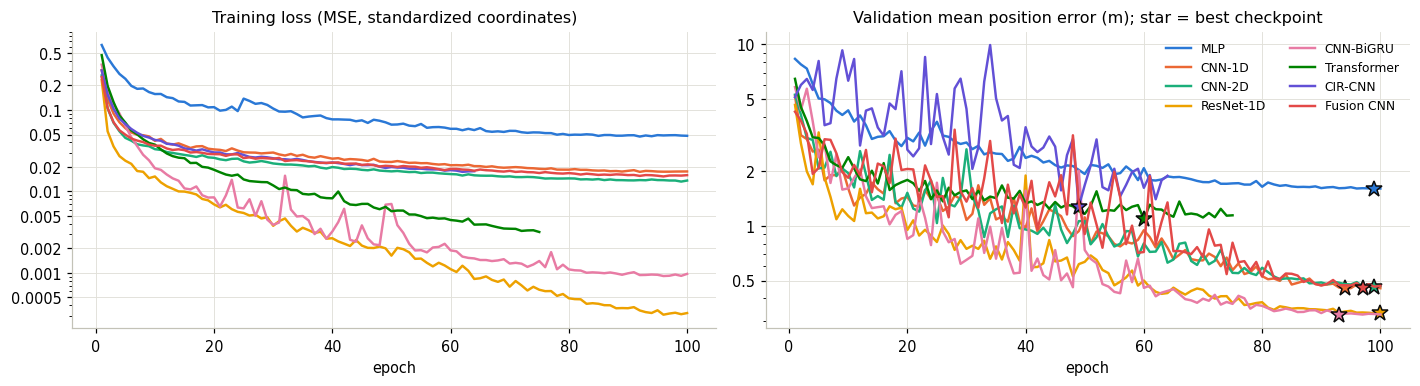

In [29]:
# Figure: ANN training curves
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for i, (name, hist) in enumerate(ann_hist.items()):
    axes[0].plot(hist['epoch'], hist['train_loss'], lw=1.6, color=PALETTE[i], label=name)
    axes[1].plot(hist['epoch'], hist['val_error_m'], lw=1.6, color=PALETTE[i], label=name)
    b = hist.attrs['best_epoch']
    axes[1].plot(b, hist.loc[b - 1, 'val_error_m'], marker='*', ms=11, color=PALETTE[i], markeredgecolor='#0b0b0b')
axes[0].set(title='Training loss (MSE, standardized coordinates)', xlabel='epoch')
log_axis(axes[0], 'y')
axes[1].set(title='Validation mean position error (m); star = best checkpoint', xlabel='epoch')
log_axis(axes[1], 'y')
axes[1].legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

### 6.2 Configuration study (CNN-1D)
One design choice is changed at a time; everything else is the baseline of Section 5 (ReLU, 2 linear outputs, MSE,
Adam, lr 1e-3, batch 64, at most `CFG_EPOCHS` epochs with early stopping, linear min-max input).

In [30]:
low = target_train.min(0).values - 0.05
high = target_train.max(0).values + 0.05
class_xy_train, class_id_train = np.unique(xy_train, axis=0, return_inverse=True)
class_xy_t = torch.tensor(class_xy_train, dtype=torch.float32, device=device)
class_id_t = torch.tensor(class_id_train.reshape(-1), dtype=torch.long, device=device)
print('reference positions (classes):', len(class_xy_train))


def run_config(study, setting, act=nn.ReLU, output='linear', loss='MSE', optimizer='Adam', lr=1e-3, batch_size=64,
               max_epochs=CFG_EPOCHS, input_key='amp'):
    set_seed()
    inputs, val_inputs = (train_gpu[input_key],), (valid_gpu[input_key],)
    if output == 'classification':
        model = make_cnn1d(len(class_xy_train), act=act)
        target, loss_fn = class_id_t, nn.CrossEntropyLoss()
    else:
        model = make_cnn1d(2, act=act)
        if output == 'bounded':
            model = nn.Sequential(model, BoundedOutput(low, high))
        target, loss_fn = target_train, LOSSES[loss]
    stop_mode = 'class (argmax)' if output == 'classification' else 'regression'
    hist, train_s = train_net(model, inputs, target, loss_fn, val_fn=val_error(val_inputs, xy_valid, stop_mode, class_xy_t),
                              max_epochs=max_epochs, lr=lr, batch_size=batch_size, optimizer=optimizer)
    modes = ['class (argmax)', 'class (expected position)'] if output == 'classification' else ['regression']
    rows = []
    for mode in modes:
        label = setting if len(modes) == 1 else f'{setting}: {mode.split("(")[1][:-1]}'
        rows.append({'study': study, 'setting': label,
                     **pos_metrics(predict_xy(model, val_inputs, mode, class_xy_t), xy_valid),
                     'best_epoch': hist.attrs['best_epoch'], 'train_s': train_s})
    return rows


STUDIES = {'Hidden activation': ('ReLU', [('LeakyReLU', dict(act=nn.LeakyReLU)), ('ELU', dict(act=nn.ELU)),
                                          ('GELU', dict(act=nn.GELU)), ('Tanh', dict(act=nn.Tanh)),
                                          ('Sigmoid', dict(act=nn.Sigmoid))]),
           'Output layer': ('2 linear neurons', [('2 bounded sigmoid neurons', dict(output='bounded')),
                                                 ('476-class softmax', dict(output='classification'))]),
           'Loss function': ('MSE', [('L1', dict(loss='L1')), ('Huber (delta 0.1)', dict(loss='Huber')),
                                     ('Euclidean distance', dict(loss='Distance'))]),
           'Optimizer': ('Adam', [('AdamW (wd 0.01)', dict(optimizer='AdamW')),
                                  ('SGD momentum (lr 0.01)', dict(optimizer='SGD', lr=1e-2)),
                                  ('RMSprop', dict(optimizer='RMSprop'))]),
           'Learning rate': ('1e-3', [('3e-3', dict(lr=3e-3)), ('3e-4', dict(lr=3e-4))]),
           'Batch size': ('64', [('32', dict(batch_size=32)), ('256', dict(batch_size=256))]),
           'Epoch budget': (f'{CFG_EPOCHS}', [(f'{max(1, CFG_EPOCHS // 2)}', dict(max_epochs=max(1, CFG_EPOCHS // 2))),
                                              (f'{MAX_EPOCHS}', dict(max_epochs=MAX_EPOCHS))]),
           'Input normalization': ('linear min-max', [('dB min-max', dict(input_key='amp_db')),
                                                      ('per-sample max', dict(input_key='amp_sample'))])}
baseline = run_config('baseline', 'baseline')[0]
rows = []
t0 = time.time()
for study, (base_label, variants) in STUDIES.items():
    rows.append({**baseline, 'study': study, 'setting': base_label + ' (baseline)'})
    for setting, kwargs in variants:
        rows += run_config(study, setting, **kwargs)
config_table = pd.DataFrame(rows)
print(f'configuration study: {time.time() - t0:.0f} s')
config_table.round(4)

reference positions (classes): 476


configuration study: 1402 s


,study,setting,mean_m,median_m,RMSE_m,p90_m,within_1m,best_epoch,train_s
0,Hidden activation,ReLU (baseline),0.5299,0.4072,0.7266,1.0073,0.8982,49,44.8024
1,Hidden activation,LeakyReLU,0.5073,0.3934,0.6860,0.9737,0.9058,49,46.8345
2,Hidden activation,ELU,0.8247,0.5883,1.1772,1.6655,0.7442,49,47.4377
3,Hidden activation,GELU,0.5005,0.3754,0.6849,0.9982,0.9000,49,46.8268
4,Hidden activation,Tanh,0.5819,0.4432,0.8257,1.1156,0.8694,49,45.1028
5,Hidden activation,Sigmoid,1.9772,1.5563,2.5313,4.0660,0.3088,49,44.5689
6,Output layer,2 linear neurons (baseline),0.5299,0.4072,0.7266,1.0073,0.8982,49,44.8024
7,Output layer,2 bounded sigmoid neurons,0.4556,0.3607,0.5945,0.8648,0.9286,50,52.4135
8,Output layer,476-class softmax: argmax,0.0000,0.0000,0.0000,0.0000,1.0000,8,21.8502
9,Output layer,476-class softmax: expected position,0.0100,0.0005,0.1234,0.0086,0.9988,8,21.8502


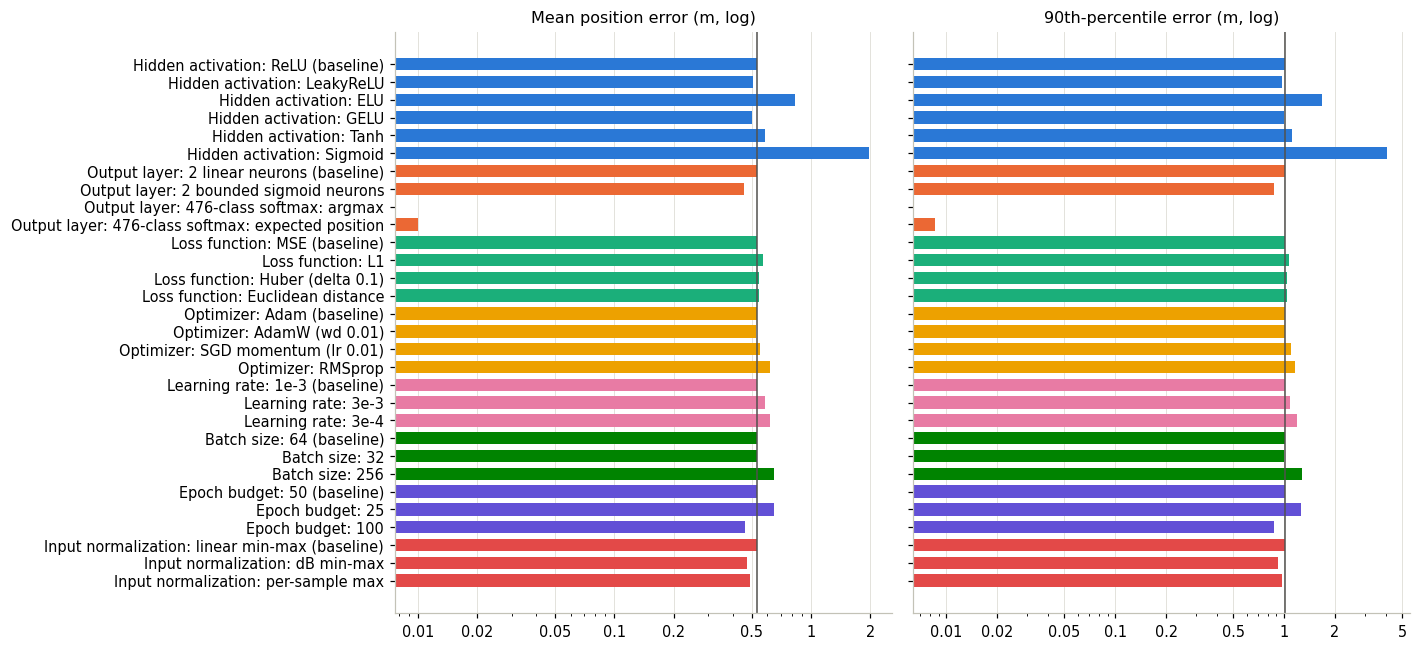

In [31]:
# Figure: configuration study
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
labels = config_table['study'] + ': ' + config_table['setting']
colors = [PALETTE[list(STUDIES).index(s)] for s in config_table['study']]
ypos = np.arange(len(config_table))[::-1]
for ax, (col, title) in zip(axes, [('mean_m', 'Mean position error (m, log)'), ('p90_m', '90th-percentile error (m, log)')]):
    ax.barh(ypos, config_table[col], color=colors, height=0.7)
    ax.axvline(baseline[col], color='#52514e', lw=1)
    log_axis(ax)
    ax.set(title=title, yticks=ypos, yticklabels=labels)
    ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

### 6.3 Tuned network
The best architecture of 6.1 is trained with the best loss function of 6.2 for at most `MAX_EPOCHS_LONG` epochs (the
epoch-budget study shows that a longer cosine schedule keeps reducing the error), with early stopping (patience 20).

In [32]:
best_arch = ann_table['mean_m'].idxmin()
loss_study = config_table[config_table['study'] == 'Loss function']
best_loss = loss_study.loc[loss_study['mean_m'].idxmin(), 'setting'].split(' (')[0]
best_loss = {'Euclidean distance': 'Distance', 'Huber': 'Huber', 'L1': 'L1'}.get(best_loss, 'MSE')
tuned_name = f'Tuned {best_arch}'
print(f'{tuned_name}: loss {best_loss}, at most {MAX_EPOCHS_LONG} epochs')
keys, build = ARCHS[best_arch]
set_seed()
tuned = build(2)
va = tuple(valid_gpu[k] for k in keys)
tuned_hist, train_s = train_net(tuned, tuple(train_gpu[k] for k in keys), target_train, LOSSES[best_loss],
                                val_fn=val_error(va, xy_valid), max_epochs=MAX_EPOCHS_LONG, patience=20)
ann_models[tuned_name], ann_hist[tuned_name] = tuned, tuned_hist
ARCHS[tuned_name] = ARCHS[best_arch]
ann_pred[tuned_name] = predict_xy(tuned, va)
ann_rows.append(ann_row(tuned_name, tuned, va, ann_pred[tuned_name], train_s, input=' + '.join(keys),
                        best_epoch=tuned_hist.attrs['best_epoch'], epochs_run=len(tuned_hist)))
print(f'mean error {ann_rows[-1]["mean_m"]:.3f} m (untuned {ann_table.loc[best_arch, "mean_m"]:.3f} m), '
      f'best epoch {tuned_hist.attrs["best_epoch"]} of {len(tuned_hist)}, training {train_s:.1f} s')

Tuned CNN-BiGRU: loss MSE, at most 200 epochs


mean error 0.232 m (untuned 0.324 m), best epoch 189 of 200, training 351.0 s


### 6.4 Multi-task network: position and LoS/NLoS with one CNN
One CNN-1D trunk with 4 outputs: 2 linear neurons for $(\tilde x, \tilde y)$ and 2 softmax neurons for LoS/NLoS.
Loss = MSE + 0.1 · cross-entropy. One network replaces two, which halves the computation on the vehicle.

In [33]:
def multitask_loss(out, target):
    return F.mse_loss(out[:, :2], target[:, :2]) + 0.1 * F.cross_entropy(out[:, 2:], target[:, 2].long())


set_seed()
mtl = make_cnn1d(4)
mtl_target = torch.cat([target_train, torch.tensor(los_train, dtype=torch.float32, device=device)[:, None]], dim=1)
mtl_hist, train_s = train_net(mtl, (train_gpu['amp'],), mtl_target, multitask_loss, val_fn=val_error((valid_gpu['amp'],), xy_valid))
out = net_output(mtl, (valid_gpu['amp'],))
mtl_los_acc = accuracy_score(los_valid, out[:, 2:].argmax(1).cpu().numpy())
name = 'Multi-task CNN-1D'
ann_models[name], ann_hist[name] = mtl, mtl_hist
ARCHS[name] = ARCHS['CNN-1D']
ann_pred[name] = decode(out)
ann_rows.append(ann_row(name, mtl, (valid_gpu['amp'],), ann_pred[name], train_s, input='amp',
                        best_epoch=mtl_hist.attrs['best_epoch'], epochs_run=len(mtl_hist)))
ann_table = pd.DataFrame(ann_rows).set_index('model')
print(f'multi-task CNN-1D: mean error {ann_table.loc[name, "mean_m"]:.3f} m (single-task CNN-1D '
      f'{ann_table.loc["CNN-1D", "mean_m"]:.3f} m) | LoS/NLoS accuracy {mtl_los_acc:.4f}')

multi-task CNN-1D: mean error 0.449 m (single-task CNN-1D 0.453 m) | LoS/NLoS accuracy 1.0000


The best validation checkpoint (lowest mean error of all networks) is saved with everything needed to reuse it:
architecture, input, scaling statistics of the training set, target mean / standard deviation and the best epoch.

In [34]:
ckpt_name = ann_table['mean_m'].idxmin()
torch.save({'architecture': ckpt_name, 'inputs': ARCHS[ckpt_name][0], 'state_dict': ann_models[ckpt_name].state_dict(),
            'best_epoch': int(ann_table.loc[ckpt_name, 'best_epoch']), 'scaling': vars(norm), 'target_mean': XY_MEAN,
            'target_std': XY_STD, 'pool': POOL, 'n_taps': N_TAPS}, 'Position_best_model.pt')
print(f'saved Position_best_model.pt: {ckpt_name}, best epoch {int(ann_table.loc[ckpt_name, "best_epoch"])}, '
      f'validation mean error {ann_table.loc[ckpt_name, "mean_m"]:.3f} m')

saved Position_best_model.pt: Tuned CNN-BiGRU, best epoch 189, validation mean error 0.232 m


# Part C — Comparative study of ML and ANN
## 7.1 Accuracy and efficiency of all final models
- **train_s**: wall-clock training time (ML on the CPU including PCA, ANN on the GPU);
- **infer_ms**: prediction time per sample for the 5000 validation samples (batch);
- **cpu_latency_ms**: time to locate one CSI report on the CPU (single sample);
- **size_MB**: storage of the model (pickled scikit-learn pipeline / PyTorch `state_dict` in float32).

In [35]:
summary = pd.concat([ml_table, ann_table])[['type', 'input', 'mean_m', 'median_m', 'RMSE_m', 'p90_m', 'within_1m',
                                            'train_s', 'infer_ms', 'cpu_latency_ms', 'size_MB', 'params', 'best_epoch']]
summary['params'] = summary['params'].astype('Int64')
summary['best_epoch'] = summary['best_epoch'].astype('Int64')          # ML models have no trainable-weight count
best_ann = ann_table['mean_m'].idxmin()
print('best ML :', best_ml, '| best ANN:', best_ann)
summary.round(4)

best ML : KNN | best ANN: Tuned CNN-BiGRU


,type,input,mean_m,median_m,RMSE_m,p90_m,within_1m,train_s,infer_ms,cpu_latency_ms,size_MB,params,best_epoch
model,,,,,,,,,,,,,
Linear Regression,ML,Physical,3.3243,2.8590,4.1229,5.9645,0.0928,0.8053,0.0176,0.9000,0.0385,<NA>,<NA>
KNN,ML,Amplitude (PCA),0.0037,0.0000,0.2363,0.0000,0.9996,1.3299,0.0431,1.2886,6.9018,<NA>,<NA>
SVR (RBF),ML,Amplitude (PCA),1.1982,0.5266,2.1662,3.0957,0.6890,101.4899,3.4837,4.8614,9.6665,<NA>,<NA>
Random Forest,ML,Amplitude (PCA),0.4686,0.1486,1.2095,1.0971,0.8878,31.6522,0.0230,8.9042,25.4576,<NA>,<NA>
Gradient Boosting,ML,Amplitude (PCA),0.9513,0.6748,1.4312,1.8833,0.6894,7.5730,0.0263,29.0704,3.2195,<NA>,<NA>
MLP,ANN,amp,1.6061,1.3695,1.9583,3.0385,0.3318,74.5651,0.0000,0.2608,3.8746,967938,99
CNN-1D,ANN,amp,0.4527,0.3515,0.6078,0.8656,0.9278,177.7240,0.0071,0.7801,0.6810,167842,94
CNN-2D,ANN,amp,0.4626,0.3626,0.6123,0.8961,0.9244,158.5636,0.0108,2.1019,0.4044,98850,99
ResNet-1D,ANN,amp,0.3299,0.2527,0.4515,0.6576,0.9692,309.4127,0.0060,2.3021,0.9382,226498,100


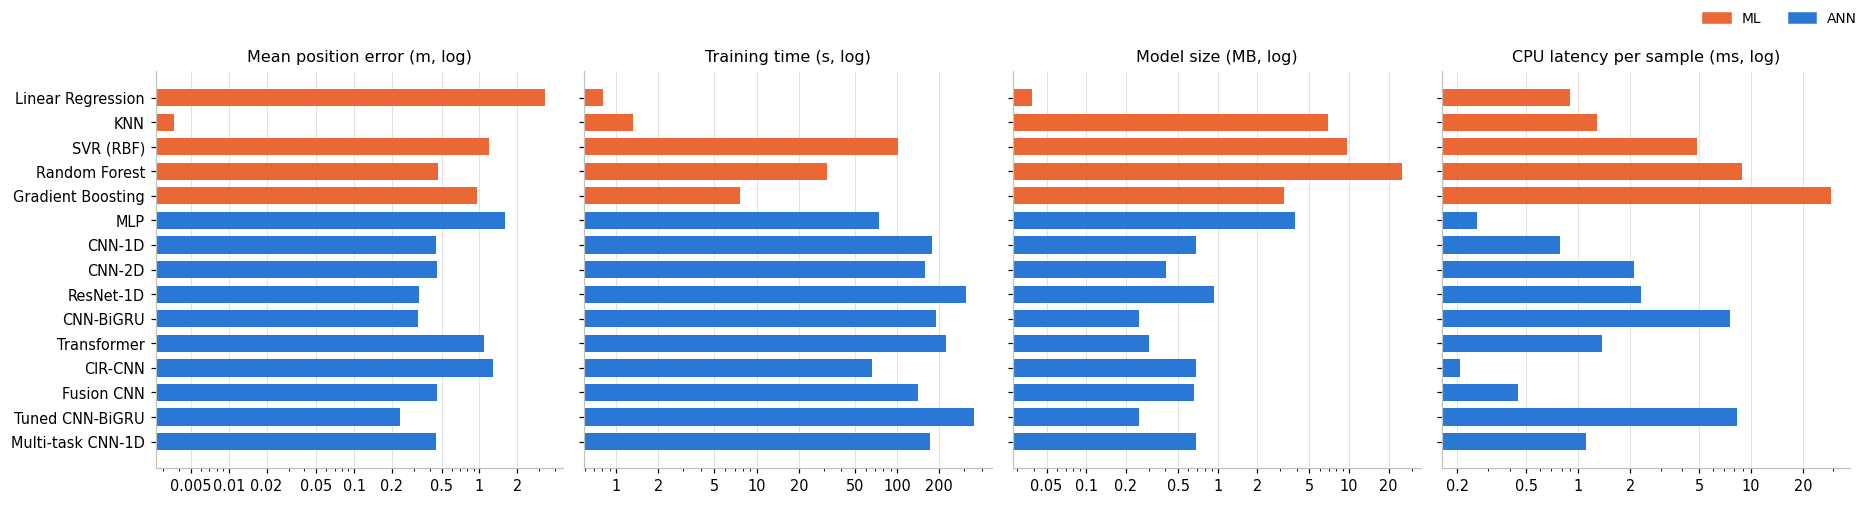

In [36]:
# Figure: comparison of all final models
fig, axes = plt.subplots(1, 4, figsize=(17, 4.6), sharey=True)
order = summary.index[::-1]
bar_colors = [COLORS[t] for t in summary.loc[order, 'type']]
for ax, (col, title) in zip(axes, [('mean_m', 'Mean position error (m, log)'), ('train_s', 'Training time (s, log)'),
                                   ('size_MB', 'Model size (MB, log)'), ('cpu_latency_ms', 'CPU latency per sample (ms, log)')]):
    ax.barh(range(len(order)), summary.loc[order, col].clip(lower=1e-3), color=bar_colors, height=0.7)
    ax.set(title=title, yticks=range(len(order)), yticklabels=order)
    ax.grid(axis='y', visible=False)
    log_axis(ax)
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLORS[t]) for t in ['ML', 'ANN']], labels=['ML', 'ANN'],
           loc='upper right', ncol=2, fontsize=9)
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

## 7.2 Error distribution
Cumulative distribution (CDF) of the position error. KNN errors of exactly 0 m are drawn at 1 mm (log axis).

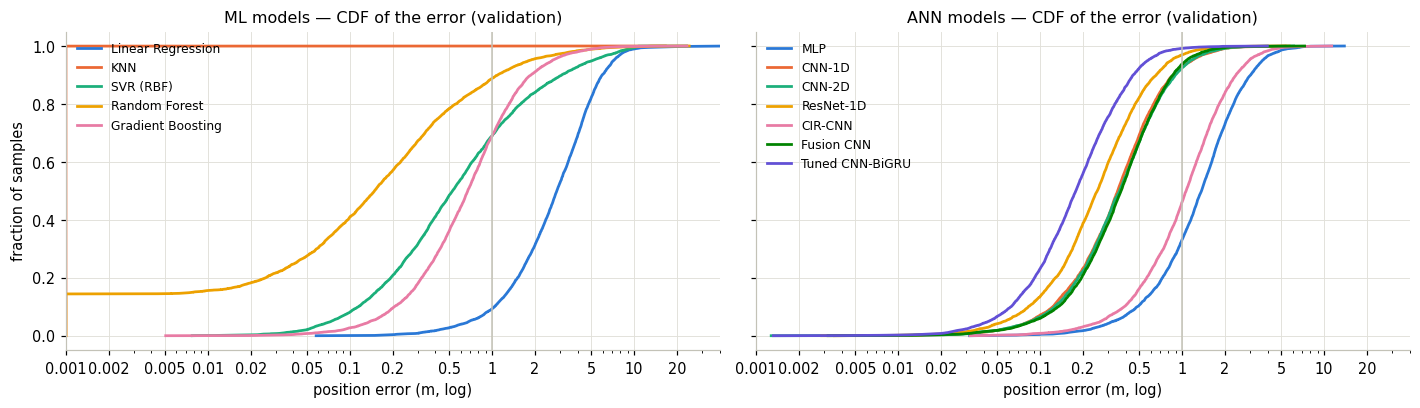

In [37]:
# Figure: CDF of the position error
all_pred = {**ml_pred, **ann_pred}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
cdf_ann = ['MLP', 'CNN-1D', 'CNN-2D', 'ResNet-1D', 'CIR-CNN', 'Fusion CNN', tuned_name]
for ax, (kind, names) in zip(axes, [('ML', list(final_ml)), ('ANN', cdf_ann)]):
    for i, name in enumerate(names):
        e = np.sort(np.maximum(position_errors(all_pred[name], xy_valid), 1e-3))
        ax.plot(e, np.arange(1, len(e) + 1) / len(e), lw=1.8, color=PALETTE[i], label=name)
    log_axis(ax)
    ax.set(xlim=(1e-3, 40), xlabel='position error (m, log)', title=f'{kind} models — CDF of the error (validation)')
    ax.axvline(1, color='#c3c2b7', lw=1)
    ax.legend(fontsize=8, loc='upper left')
axes[0].set_ylabel('fraction of samples')
plt.tight_layout()
plt.show()

Predicted positions (coloured) against the true measurement positions (grey) for three models.

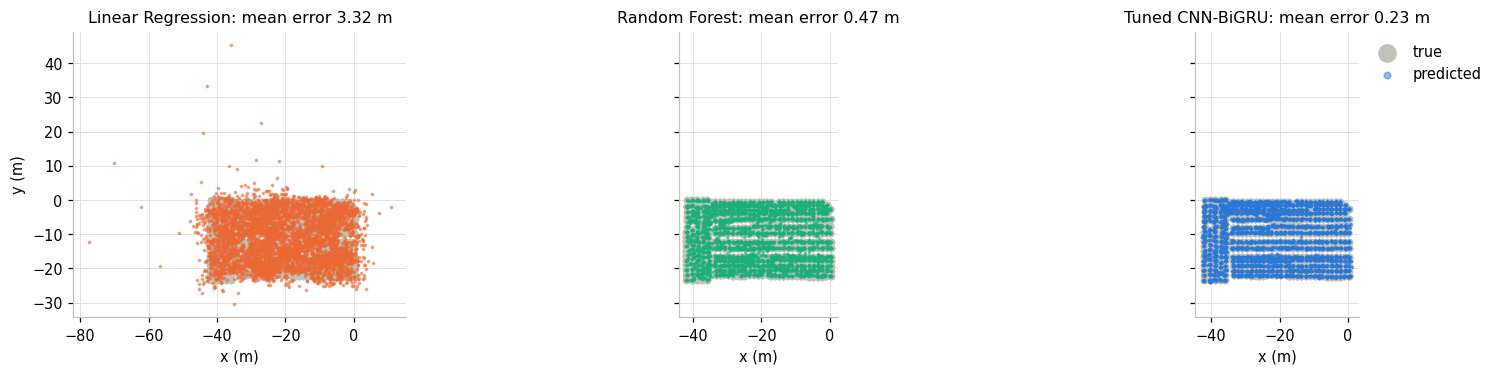

In [38]:
# Figure: predicted vs true positions
shown = ['Linear Regression', 'Random Forest', best_ann]
fig, axes = plt.subplots(1, 3, figsize=(16, 3.5), sharey=True)
for ax, name, color in zip(axes, shown, [PALETTE[1], PALETTE[2], PALETTE[0]]):
    ax.scatter(xy_valid[:, 0], xy_valid[:, 1], s=14, color='#c3c2b7', label='true')
    ax.scatter(all_pred[name][:, 0], all_pred[name][:, 1], s=2, color=color, alpha=0.5, label='predicted')
    ax.set(title=f'{name}: mean error {position_errors(all_pred[name], xy_valid).mean():.2f} m', xlabel='x (m)')
    ax.set_aspect('equal')
axes[0].set_ylabel('y (m)')
axes[-1].legend(loc='upper left', bbox_to_anchor=(1, 1), markerscale=3)
plt.tight_layout()
plt.show()

## 7.3 Error for LoS and NLoS positions, and where the errors are

In [39]:
los_table = pd.DataFrame({name: {'LoS mean error (m)': position_errors(p, xy_valid)[los_valid == 0].mean(),
                                 'NLoS mean error (m)': position_errors(p, xy_valid)[los_valid == 1].mean()}
                          for name, p in all_pred.items()}).T
los_table['NLoS / LoS'] = los_table['NLoS mean error (m)'] / los_table['LoS mean error (m)']
los_table.round(4)

,LoS mean error (m),NLoS mean error (m),NLoS / LoS
Linear Regression,3.3921,3.0301,0.8933
KNN,0.0045,0.0000,0.0000
SVR (RBF),1.1298,1.4952,1.3234
Random Forest,0.3948,0.7892,1.9989
Gradient Boosting,0.8842,1.2425,1.4053
MLP,1.6396,1.4606,0.8909
CNN-1D,0.4316,0.5444,1.2612
CNN-2D,0.4367,0.5750,1.3167
ResNet-1D,0.3186,0.3786,1.1882
CNN-BiGRU,0.3050,0.4080,1.3376


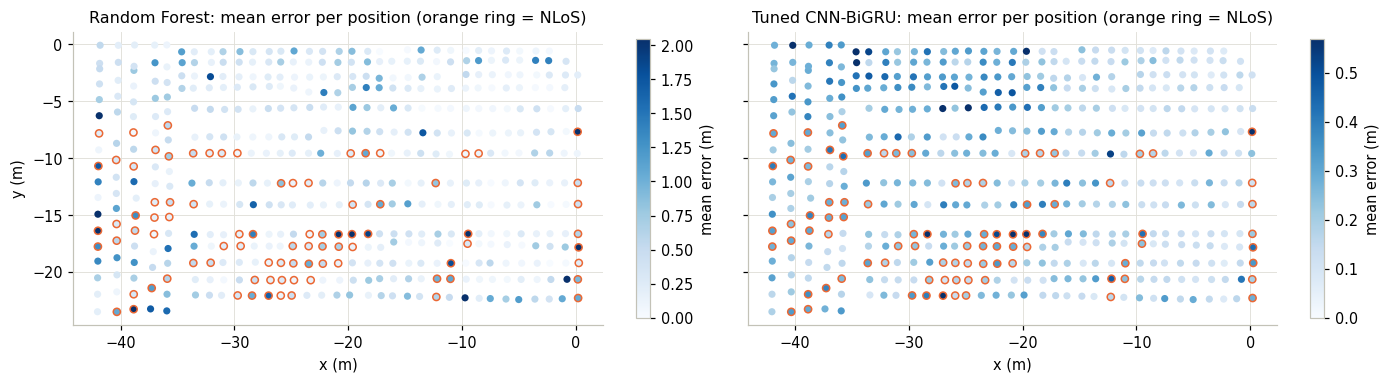

In [40]:
# Figure: mean error per position
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4), sharey=True)
for ax, name in zip(axes, ['Random Forest', best_ann]):
    e = position_errors(all_pred[name], xy_valid)
    per_pos = pd.DataFrame({'x': xy_valid[:, 0], 'y': xy_valid[:, 1], 'e': e, 'los': los_valid}).groupby(['x', 'y']).mean().reset_index()
    sc = ax.scatter(per_pos['x'], per_pos['y'], c=per_pos['e'], cmap='Blues', s=22, vmin=0,
                    vmax=np.percentile(per_pos['e'], 98), edgecolors=np.where(per_pos['los'] > 0.5, PALETTE[1], 'none'),
                    linewidths=1)
    plt.colorbar(sc, ax=ax, label='mean error (m)', shrink=0.85)
    ax.set(title=f'{name}: mean error per position (orange ring = NLoS)', xlabel='x (m)')
    ax.set_aspect('equal')
axes[0].set_ylabel('y (m)')
plt.tight_layout()
plt.show()

# Part D — Extra studies
## 8. Robustness on an emulated unreliable network
The models are trained on clean CSI and tested, **without retraining**, on corrupted copies of the validation CSI:
- **noisy CSI**: complex white Gaussian noise at a per-sample SNR of 30 … 0 dB;
- **lost CSI packets**: the 1632 subcarriers travel in 16 packets of 102 subcarriers (all 4 antennas); each packet
  is lost with probability *p* and the missing values are zero;
- **lost packets + repair** (receiver-side defence): the receiver knows which packets are missing. The CSI is
  de-rotated by the delay of the strongest path, the missing subcarriers are linearly interpolated from the received
  ones, and the rotation is applied again.

All inputs are recomputed from the corrupted complex CSI by `preprocess`. A second defence is **data augmentation**:
a CNN-1D trained on corrupted training CSI generated on the fly (with probability 0.5 noise at a random SNR of
0–30 dB, with probability 0.5 a random packet-loss rate of 0–50 %).

In [41]:
N_PACKETS = 16


def add_awgn(H, snr_db, generator=None):
    """Complex white Gaussian noise; the SNR (dB, scalar or one value per sample) uses the mean |H|^2 of each sample."""
    power = H.abs().pow(2).mean(dim=(-2, -1), keepdim=True)
    snr = torch.as_tensor(snr_db, dtype=torch.float32, device=H.device)
    std = torch.sqrt(power / (2 * 10 ** (snr / 10)))
    noise = torch.view_as_complex(torch.randn(*H.shape, 2, generator=generator, device=H.device))
    return H + std * noise


def packet_mask(n, rate, generator=None, device='cpu'):
    """True = subcarrier lost. Each packet of 102 subcarriers is lost with probability `rate`."""
    lost = torch.rand(n, N_PACKETS, generator=generator, device=device) < rate
    return lost.repeat_interleave(1632 // N_PACKETS, dim=1)


def drop_packets(H, mask):
    return H * (~mask)[:, None, :]


def repair_packets(H, mask):
    """Interpolate the lost subcarriers of the CSI after removing the phase slope of the strongest path."""
    n_sc = H.shape[-1]
    k = torch.arange(n_sc)
    delay = torch.fft.ifft(H, dim=-1).abs().pow(2).sum(1).argmax(-1)
    rot = torch.exp(2j * np.pi * k[None, :] * delay[:, None] / n_sc).to(torch.complex64)
    Hd = (H * rot[:, None, :]).numpy()
    m, kk = mask.numpy(), np.arange(n_sc)
    for i in np.flatnonzero(m.any(1) & ~m.all(1)):
        lost, ok = m[i], ~m[i]
        for a in range(Hd.shape[1]):
            Hd[i, a, lost] = (np.interp(kk[lost], kk[ok], Hd[i, a, ok].real) +
                              1j * np.interp(kk[lost], kk[ok], Hd[i, a, ok].imag))
    return torch.from_numpy(Hd) * rot.conj()[:, None, :]


def amp_input(H, nrm):
    """complex CSI -> normalized amplitude input, exactly as in `preprocess` (works on the GPU)."""
    return (F.avg_pool1d(H.abs(), POOL) - nrm.amp_min) / (nrm.amp_max - nrm.amp_min)


def make_augment(nrm):
    """On-the-fly corruption of a training batch, scaled with the statistics `nrm` of the training data."""
    def augment(H):
        n, dev = len(H), H.device
        noisy = add_awgn(H, torch.empty(n, 1, 1, device=dev).uniform_(0, 30))
        H = torch.where(torch.rand(n, 1, 1, device=dev) < 0.5, noisy, H)
        mask = packet_mask(n, torch.empty(n, 1, device=dev).uniform_(0, 0.5), device=dev)
        mask &= torch.rand(n, 1, device=dev) < 0.5
        return (amp_input(drop_packets(H, mask), nrm),)
    return augment

In [42]:
set_seed()
aug_model = make_cnn1d(2)
aug_hist, aug_train_s = train_net(aug_model, (train_CSI,), target_train, LOSSES['MSE'],
                                  val_fn=val_error((valid_gpu['amp'],), xy_valid), transform=make_augment(norm))
aug_err = position_errors(predict_xy(aug_model, (valid_gpu['amp'],)), xy_valid).mean()
print(f'CNN-1D + augmentation: clean validation mean error {aug_err:.3f} m, best epoch {aug_hist.attrs["best_epoch"]}, '
      f'training {aug_train_s:.1f} s')

CNN-1D + augmentation: clean validation mean error 0.560 m, best epoch 98, training 216.8 s


In [43]:
ROBUST_ANN = {name: (ann_models[name], ARCHS[name][0]) for name in ['MLP', 'CNN-1D', 'CNN-2D', 'ResNet-1D', 'CIR-CNN', 'Fusion CNN']}
ROBUST_ANN['CNN-1D + augmentation'] = (aug_model, ('amp',))


def predict_pos(name, inputs):
    if name in final_ml:
        fs, model = final_ml[name]
        return model.predict(ml_matrix(inputs, fs))
    model, keys = ROBUST_ANN[name]
    return predict_xy(model, tuple(inputs[k].to(device) for k in keys))


SNRS, LOSS_RATES = [30, 20, 10, 5, 0], [0.1, 0.2, 0.3, 0.5]
robust_names = list(final_ml) + list(ROBUST_ANN)
generator = torch.Generator().manual_seed(SEED)


def error_rows(corruption, level, inputs):
    return [{'corruption': corruption, 'level': level, 'model': n,
             'mean_m': position_errors(predict_pos(n, inputs), xy_valid).mean()} for n in robust_names]


t0 = time.time()
rows = error_rows('clean', 0, valid_in)
for snr in SNRS:
    rows += error_rows('noise', snr, preprocess(add_awgn(valid_CSI, snr, generator)))
for rate in LOSS_RATES:
    mask = packet_mask(len(valid_CSI), rate, generator)
    lossy = drop_packets(valid_CSI, mask)
    rows += error_rows('packet loss', rate, preprocess(lossy))
    rows += error_rows('packet loss + repair', rate, preprocess(repair_packets(lossy, mask)))
robust = pd.DataFrame(rows)
print(f'robustness test: {time.time() - t0:.0f} s')
clean_err = robust[robust['corruption'] == 'clean'].set_index('model')['mean_m']


def pivot(corruption):
    r = robust[robust['corruption'] == corruption]
    return r.pivot(index='model', columns='level', values='mean_m').loc[robust_names]


def curve(corruption, name):
    r = robust[(robust['corruption'] == corruption) & (robust['model'] == name)]
    return r['level'].tolist(), r['mean_m'].tolist()


noise_table = pivot('noise')[SNRS].rename(columns=lambda s: f'{s:g} dB')
noise_table.insert(0, 'clean', clean_err)
noise_table.round(3)

robustness test: 198 s


level,clean,30 dB,20 dB,10 dB,5 dB,0 dB
model,,,,,,
Linear Regression,3.324,3.327,3.938,9.592,21.146,58.320
KNN,0.004,0.004,0.004,0.004,0.023,5.675
SVR (RBF),1.198,1.211,1.299,2.168,4.142,7.921
Random Forest,0.469,0.488,0.632,1.976,4.474,8.179
Gradient Boosting,0.951,0.971,1.121,2.355,4.564,8.216
MLP,1.606,1.610,1.662,2.610,6.091,12.175
CNN-1D,0.453,0.467,0.642,2.871,6.759,11.712
CNN-2D,0.463,0.490,0.834,3.942,7.691,12.057
ResNet-1D,0.330,0.346,0.555,3.183,7.058,11.226


In [44]:
loss_table = pd.concat({c: pivot(c)[LOSS_RATES] for c in ['packet loss', 'packet loss + repair']}, axis=1)
loss_table.insert(0, ('clean', 0), clean_err)
loss_table.round(3)

clean packet loss                                \
level                    0.0         0.1       0.2       0.3       0.5   
model                                                                    
Linear Regression      3.324     907.914  1588.324  2034.243  2293.885   
KNN                    0.004       1.776     5.520     9.465    15.835   
SVR (RBF)              1.198       7.649     9.560    10.304    11.062   
Random Forest          0.469       6.613     8.795     9.812    10.834   
Gradient Boosting      0.951       6.714     8.866     9.814    10.578   
MLP                    1.606       5.844     7.891     9.202    10.949   
CNN-1D                 0.453       4.473     7.141     9.243    11.995   
CNN-2D                 0.463       4.554     7.488    10.000    14.288   
ResNet-1D              0.330       2.998     5.295     7.471    11.565   
CIR-CNN                1.277       3.842     5.442     6.574     8.343   
Fusion CNN             0.456       3.879     6.048     7.797     9.963   
CNN-1D + augmentation  0.560       0.829     1.074     1.401     2.410   

                      packet loss + repair                       
level                                  0.1    0.2    0.3    0.5  
model                                                            
Linear Regression                    4.083  4.798  5.797  8.620  
KNN                                  0.005  0.020  0.082  0.879  
SVR (RBF)                            2.195  3.208  4.166  6.484  
Random Forest                        2.087  3.388  4.351  6.173  
Gradient Boosting                    2.349  3.436  4.341  6.027  
MLP                                  2.189  2.895  3.630  5.261  
CNN-1D                               1.024  1.644  2.312  4.098  
CNN-2D                               1.085  1.784  2.542  4.533  
ResNet-1D                            1.048  1.796  2.664  4.612  
CIR-CNN                              1.709  2.208  2.724  4.072  
Fusion CNN                           0.917  1.404  1.945  3.398  
CNN-1D + augmentation                0.999  1.518  2.091  3.609

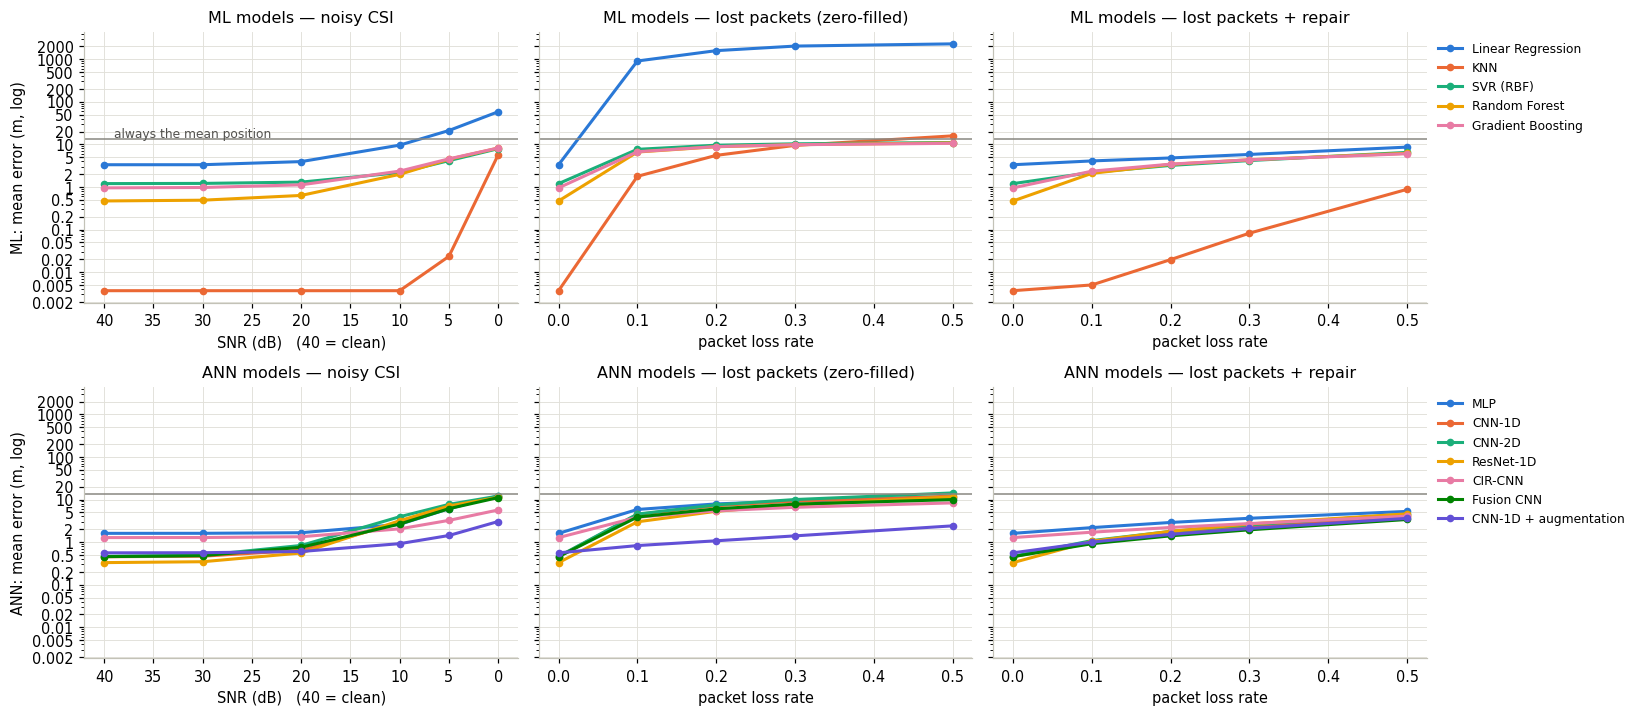

In [45]:
# Figure: robustness to noise and packet loss
fig, axes = plt.subplots(2, 3, figsize=(15, 6.6), sharey=True)
groups = [('ML', list(final_ml)), ('ANN', list(ROBUST_ANN))]
for row, (kind, names) in enumerate(groups):
    for i, name in enumerate(names):
        level, err = curve('noise', name)
        axes[row, 0].plot([40] + level, np.maximum([clean_err[name]] + err, 1e-3), marker='o', ms=4, color=PALETTE[i], label=name)
        for col, corruption in [(1, 'packet loss'), (2, 'packet loss + repair')]:
            level, err = curve(corruption, name)
            axes[row, col].plot([0] + level, np.maximum([clean_err[name]] + err, 1e-3), marker='o', ms=4, color=PALETTE[i], label=name)
    axes[row, 0].set(xlabel='SNR (dB)   (40 = clean)', ylabel=f'{kind}: mean error (m, log)', title=f'{kind} models — noisy CSI')
    axes[row, 0].invert_xaxis()
    axes[row, 1].set(xlabel='packet loss rate', title=f'{kind} models — lost packets (zero-filled)')
    axes[row, 2].set(xlabel='packet loss rate', title=f'{kind} models — lost packets + repair')
    axes[row, 2].legend(loc='upper left', bbox_to_anchor=(1, 1), fontsize=8)
for ax in axes.flat:
    ax.axhline(trivial, color='#898781', lw=1)
log_axis(axes[0, 0], 'y')
axes[0, 0].text(39, trivial * 1.1, 'always the mean position', fontsize=8, color='#52514e')
plt.tight_layout()
plt.show()

## 9. Generalization to positions never seen in training
The official training and validation sets contain the **same 476 positions**, so a model can reach a small
validation error by recognising the fingerprint of a known position (KNN does exactly this). To measure
generalization, all 20,000 samples are split **by position** (`GroupShuffleSplit`): the samples of 80 % of the
positions are used for training and those of the other 20 % — positions never seen in training — for testing. The
final configurations are trained again on the seen positions only:
- all scaling statistics (min-max, PCA, standardization, target mean / std) are recomputed from the **seen** positions;
- early stopping of the networks uses an **inner validation split** (15 % of the seen positions); the unseen test
  positions are used only once, for the final evaluation.

The position-classification network uses its training positions as classes, so its "expected position" output has to
interpolate between them.

In [46]:
all_phys = np.vstack([train_in['phys'], valid_in['phys']])
xy_all = np.vstack([xy_train, xy_valid])
los_all = np.concatenate([los_train, los_valid])
position_id = np.unique(xy_all, axis=0, return_inverse=True)[1].reshape(-1)
seen, unseen = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(xy_all, groups=position_id))
assert not set(position_id[seen]) & set(position_id[unseen])        # no position in both parts
seen_t, unseen_t = torch.from_numpy(seen), torch.from_numpy(unseen)
norm_seen = Normalizer(RAW['amp'][seen_t], RAW['cir'][seen_t])        # statistics of the seen positions only
seen_in = {**norm_seen(RAW['amp'][seen_t], RAW['cir'][seen_t]), 'phys': all_phys[seen]}
unseen_in = {**norm_seen(RAW['amp'][unseen_t], RAW['cir'][unseen_t]), 'phys': all_phys[unseen]}
xy_seen, xy_unseen = xy_all[seen], xy_all[unseen]
fit_part, stop_part = next(GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED).split(seen, groups=position_id[seen]))
print(f'network training positions {len(np.unique(position_id[seen][fit_part]))}, early-stopping positions '
      f'{len(np.unique(position_id[seen][stop_part]))} (both inside the seen positions)')
seen_positions = np.unique(xy_seen, axis=0)
nearest = np.linalg.norm(np.unique(xy_unseen, axis=0)[:, None] - seen_positions[None], axis=2).min(1)
print(f'positions: {position_id.max() + 1} | seen {len(seen_positions)} | unseen {len(np.unique(xy_unseen, axis=0))}')
print(f'samples  : seen {len(seen)} | unseen {len(unseen)}')
print(f'distance from an unseen position to the nearest seen position: mean {nearest.mean():.2f} m '
      f'(lower bound of a pure look-up)')
print(f'always predicting the mean seen position: mean error {position_errors(np.tile(xy_seen.mean(0), (len(unseen), 1)), xy_unseen).mean():.2f} m')

network training positions 323, early-stopping positions 57 (both inside the seen positions)
positions: 476 | seen 380 | unseen 96
samples  : seen 15919 | unseen 4081
distance from an unseen position to the nearest seen position: mean 1.18 m (lower bound of a pure look-up)
always predicting the mean seen position: mean error 13.90 m


In [47]:
unseen_pred, unseen_rows = {}, []
for name, (fs, model) in final_ml.items():
    r, unseen_pred[name] = fit_ml(clone(model), ml_matrix(seen_in, fs), xy_seen, ml_matrix(unseen_in, fs), xy_unseen)
    unseen_rows.append({'model': name, 'type': 'ML', **{k: r[k] for k in ['mean_m', 'median_m', 'p90_m', 'train_s']}})
    print(f'{name:22s} mean error {r["mean_m"]:.2f} m')
seen_gpu = {k: seen_in[k].to(device) for k in ['amp', 'cir']}
unseen_gpu = {k: unseen_in[k].to(device) for k in ['amp', 'cir']}
fit_t, stop_t = torch.as_tensor(fit_part, device=device), torch.as_tensor(stop_part, device=device)
seen_mean, seen_std = torch.tensor(xy_seen.mean(0), dtype=torch.float32, device=device), torch.tensor(xy_seen.std(0), dtype=torch.float32, device=device)
target_seen = (torch.tensor(xy_seen, dtype=torch.float32, device=device) - seen_mean) / seen_std
mean_t, std_t = seen_mean, seen_std                     # decode() now uses the statistics of the seen positions
fit_CSI = torch.cat([train_CSI, valid_CSI.to(device)])[seen_t.to(device)][fit_t]
UNSEEN_CLS = 'CNN-1D (position softmax)'
for name in list(ROBUST_ANN) + [UNSEEN_CLS]:
    set_seed()
    mode, class_xy, keys = 'regression', None, ('amp',)
    if name == UNSEEN_CLS:
        class_xy_fit, class_id_fit = np.unique(xy_seen[fit_part], axis=0, return_inverse=True)
        class_xy, mode = torch.tensor(class_xy_fit, dtype=torch.float32, device=device), 'class (expected position)'
        model = make_cnn1d(len(class_xy_fit))
        target, loss_fn = torch.tensor(class_id_fit.reshape(-1), device=device), nn.CrossEntropyLoss()
    elif name == 'CNN-1D + augmentation':
        model, target, loss_fn = make_cnn1d(2), target_seen[fit_t], LOSSES['MSE']
    else:
        keys, build = ARCHS[name]
        model, target, loss_fn = build(2), target_seen[fit_t], LOSSES['MSE']
    stop_fn = val_error(tuple(seen_gpu[k][stop_t] for k in keys), xy_seen[stop_part], mode, class_xy)
    if name == 'CNN-1D + augmentation':
        hist, train_s = train_net(model, (fit_CSI,), target, loss_fn, val_fn=stop_fn, transform=make_augment(norm_seen))
    else:
        hist, train_s = train_net(model, tuple(seen_gpu[k][fit_t] for k in keys), target, loss_fn, val_fn=stop_fn)
    unseen_pred[name] = predict_xy(model, tuple(unseen_gpu[k] for k in keys), mode, class_xy)
    r = pos_metrics(unseen_pred[name], xy_unseen)
    unseen_rows.append({'model': name, 'type': 'ANN', **{k: r[k] for k in ['mean_m', 'median_m', 'p90_m']},
                        'train_s': train_s, 'best_epoch': hist.attrs['best_epoch']})
    print(f'{name:26s} mean error {r["mean_m"]:.2f} m (best epoch {hist.attrs["best_epoch"]})')
del fit_CSI
mean_t, std_t = torch.tensor(XY_MEAN, dtype=torch.float32, device=device), torch.tensor(XY_STD, dtype=torch.float32, device=device)
unseen_table = pd.DataFrame(unseen_rows).set_index('model')
unseen_table.round(3)

Linear Regression      mean error 7.63 m


KNN                    mean error 11.04 m


SVR (RBF)              mean error 11.36 m


Random Forest          mean error 9.76 m


Gradient Boosting      mean error 9.51 m


...

CIR-CNN                    mean error 6.11 m (best epoch 10)


Fusion CNN                 mean error 5.78 m (best epoch 24)


CNN-1D + augmentation      mean error 6.85 m (best epoch 24)


CNN-1D (position softmax)  mean error 8.73 m (best epoch 1)


,type,mean_m,median_m,p90_m,train_s,best_epoch
model,,,,,,
Linear Regression,ML,7.632,6.335,13.278,0.865,NaN
KNN,ML,11.044,8.858,23.386,1.406,NaN
SVR (RBF),ML,11.360,10.571,18.867,110.006,NaN
Random Forest,ML,9.756,8.990,17.213,42.351,NaN
Gradient Boosting,ML,9.511,8.877,15.764,7.408,NaN
MLP,ANN,9.517,8.054,16.523,32.594,32.0
CNN-1D,ANN,7.289,6.975,12.486,30.449,9.0
CNN-2D,ANN,6.485,5.545,11.261,72.079,40.0
ResNet-1D,ANN,5.460,4.834,10.486,140.580,34.0


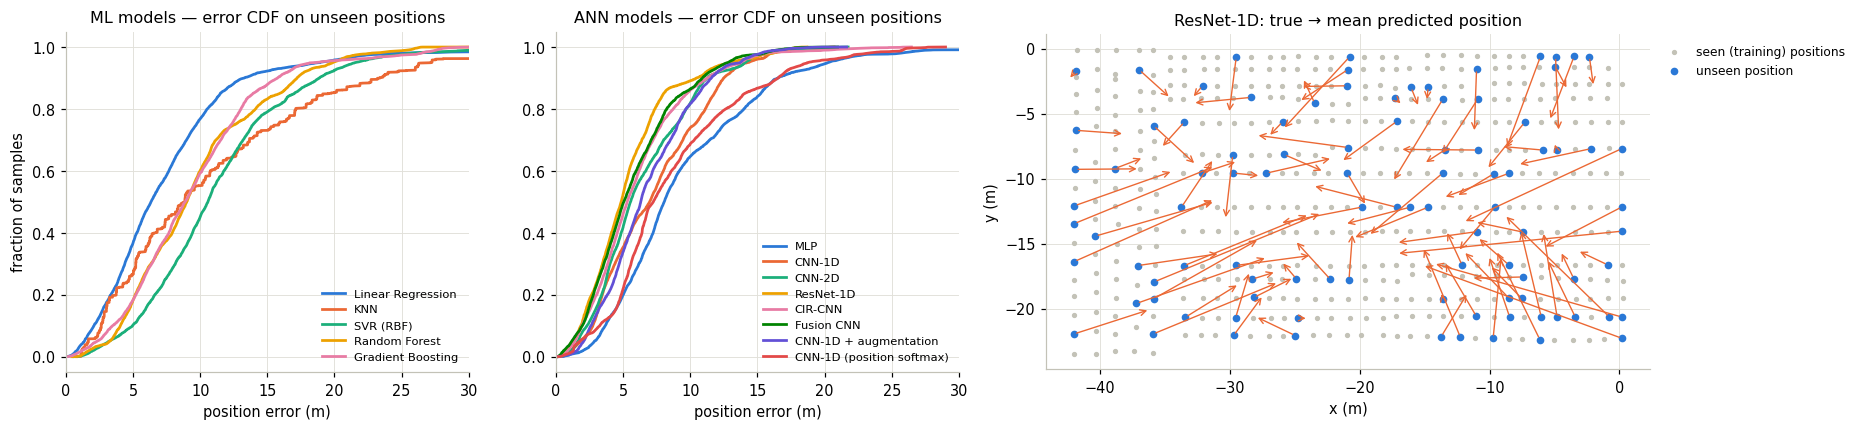

In [48]:
# Figure: unseen positions - CDF and mean predicted position
fig, axes = plt.subplots(1, 3, figsize=(17, 4), gridspec_kw={'width_ratios': [1, 1, 1.5]})
unseen_ann = list(ROBUST_ANN) + [UNSEEN_CLS]
for ax, (kind, names) in zip(axes[:2], [('ML', list(final_ml)), ('ANN', unseen_ann)]):
    for i, name in enumerate(names):
        e = np.sort(position_errors(unseen_pred[name], xy_unseen))
        ax.plot(e, np.arange(1, len(e) + 1) / len(e), lw=1.8, color=PALETTE[i], label=name.replace(' (expected position)', ''))
    ax.set(xlim=(0, 30), xlabel='position error (m)', title=f'{kind} models — error CDF on unseen positions')
    ax.legend(fontsize=7.5, loc='lower right')
axes[0].set_ylabel('fraction of samples')
best_unseen = unseen_table['mean_m'].idxmin()
per_pos = pd.DataFrame({'x': xy_unseen[:, 0], 'y': xy_unseen[:, 1], 'px': unseen_pred[best_unseen][:, 0],
                        'py': unseen_pred[best_unseen][:, 1]}).groupby(['x', 'y']).mean().reset_index()
axes[2].scatter(seen_positions[:, 0], seen_positions[:, 1], s=6, color='#c3c2b7', label='seen (training) positions')
axes[2].scatter(per_pos['x'], per_pos['y'], s=16, color=PALETTE[0], label='unseen position')
for _, r in per_pos.iterrows():
    axes[2].annotate('', xy=(r['px'], r['py']), xytext=(r['x'], r['y']),
                     arrowprops=dict(arrowstyle='->', color=PALETTE[1], lw=0.9))
axes[2].set(title=f'{best_unseen}: true → mean predicted position', xlabel='x (m)', ylabel='y (m)')
axes[2].set_aspect('equal')
axes[2].legend(loc='upper left', bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout()
plt.show()

## 10. Summary of the key results
Final comparison on the official validation set (known positions) and mean error on the unseen positions.

In [49]:
final_table = summary[['type', 'mean_m', 'median_m', 'p90_m', 'best_epoch', 'train_s', 'cpu_latency_ms', 'size_MB']].join(
    unseen_table[['mean_m']].rename(columns={'mean_m': 'unseen_mean_m'})).round(3)
final_table

,type,mean_m,median_m,p90_m,best_epoch,train_s,cpu_latency_ms,size_MB,unseen_mean_m
model,,,,,,,,,
Linear Regression,ML,3.324,2.859,5.965,<NA>,0.805,0.900,0.039,7.632
KNN,ML,0.004,0.000,0.000,<NA>,1.330,1.289,6.902,11.044
SVR (RBF),ML,1.198,0.527,3.096,<NA>,101.490,4.861,9.666,11.360
Random Forest,ML,0.469,0.149,1.097,<NA>,31.652,8.904,25.458,9.756
Gradient Boosting,ML,0.951,0.675,1.883,<NA>,7.573,29.070,3.219,9.511
MLP,ANN,1.606,1.370,3.038,99,74.565,0.261,3.875,9.517
CNN-1D,ANN,0.453,0.352,0.866,94,177.724,0.780,0.681,7.289
CNN-2D,ANN,0.463,0.363,0.896,99,158.564,2.102,0.404,6.485
ResNet-1D,ANN,0.330,0.253,0.658,100,309.413,2.302,0.938,5.460


In [50]:
key = {'validation (known positions)': summary[['type', 'mean_m', 'median_m', 'RMSE_m', 'p90_m', 'within_1m', 'train_s',
                                                'cpu_latency_ms', 'size_MB', 'params', 'best_epoch']].round(4).to_dict('index'),
       'training': {'max_epochs': MAX_EPOCHS, 'max_epochs_tuned': MAX_EPOCHS_LONG, 'patience': PATIENCE,
                    'config_max_epochs': CFG_EPOCHS, 'patience_tuned': 20,
                    'checkpoint': ckpt_name, 'augmented_best_epoch': aug_hist.attrs['best_epoch']},
       'unseen positions': unseen_table[['mean_m', 'median_m', 'p90_m']].round(3).to_dict('index'),
       'noise mean error': noise_table.round(3).to_dict('index'),
       'packet loss mean error': {m: {f'{c} {l}': v for (c, l), v in row.items()} for m, row in loss_table.round(3).to_dict('index').items()},
       'LoS/NLoS error': los_table.round(3).to_dict('index'),
       'multi-task LoS accuracy': mtl_los_acc, 'path-loss exponent': exponent,
       'best ML': best_ml, 'best ANN': best_ann, 'best unseen': best_unseen, 'tuned': tuned_name, 'tuned loss': best_loss}
print(json.dumps(key, indent=1, default=str))

{
 "validation (known positions)": {
  "Linear Regression": {
   "type": "ML",
   "mean_m": 3.3243,
   "median_m": 2.859,
   "RMSE_m": 4.1229,
   "p90_m": 5.9645,
   "within_1m": 0.0928,
   "train_s": 0.8053,
   "cpu_latency_ms": 0.9,
   "size_MB": 0.0385,
   "params": null,
   "best_epoch": null
  },
  "KNN": {
   "type": "ML",
   "mean_m": 0.0037,
   "median_m": 0.0,
   "RMSE_m": 0.2363,
   "p90_m": 0.0,
   "within_1m": 0.9996,
   "train_s": 1.3299,
   "cpu_latency_ms": 1.2886,
   "size_MB": 6.9018,
   "params": null,
   "best_epoch": null
  },
  "SVR (RBF)": {
   "type": "ML",
   "mean_m": 1.1982,
   "median_m": 0.5266,
   "RMSE_m": 2.1662,
   "p90_m": 3.0957,
   "within_1m": 0.689,
   "train_s": 101.4899,
   "cpu_latency_ms": 4.8614,
   "size_MB": 9.6665,
   "params": null,
   "best_epoch": null
  },
  "Random Forest": {
   "type": "ML",
   "mean_m": 0.4686,
   "median_m": 0.1486,
   "RMSE_m": 1.2095,
   "p90_m": 1.0971,
   "within_1m": 0.8878,
   "train_s": 31.6522,
   "cpu_latenc

## 11. Compact figures for the report
The main results drawn again at the size of an IEEE column (3.45 in) with 8-pt text.
ML models are drawn with dashed lines and ANN models with solid lines.

In [51]:
REPORT_RC = {'font.family': 'serif', 'font.serif': ['Times New Roman', 'DejaVu Serif'], 'mathtext.fontset': 'stix',
             'font.size': 8, 'axes.titlesize': 8, 'axes.labelsize': 8, 'xtick.labelsize': 7.5, 'ytick.labelsize': 7.5,
             'legend.fontsize': 6.8, 'lines.linewidth': 1.3, 'lines.markersize': 3, 'figure.dpi': 220}
COL = 3.45
REPORT_MODELS = ['Linear Regression', 'SVR (RBF)', 'Random Forest', 'Gradient Boosting', 'KNN', 'MLP', 'CNN-1D', tuned_name]
MODEL_STYLE = {name: dict(color=PALETTE[i], ls='--' if name in final_ml else '-') for i, name in enumerate(REPORT_MODELS)}

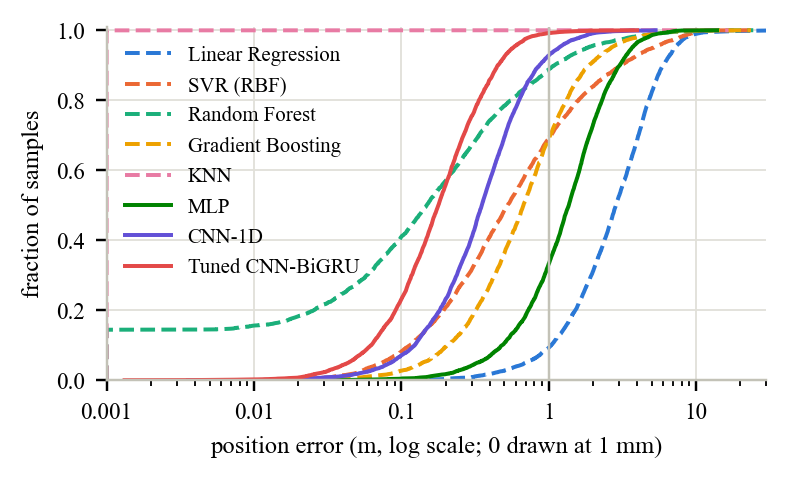

In [52]:
# Figure: report - error CDF
with plt.rc_context(REPORT_RC):
    fig, ax = plt.subplots(figsize=(COL, 2.05))
    for name in REPORT_MODELS:
        e = np.sort(np.maximum(position_errors(all_pred[name], xy_valid), 1e-3))
        ax.plot(e, np.arange(1, len(e) + 1) / len(e), label=name, **MODEL_STYLE[name])
    log_axis(ax, subs=(1,))
    ax.set(xlim=(1e-3, 30), ylim=(0, 1.01), xlabel='position error (m, log scale; 0 drawn at 1 mm)',
           ylabel='fraction of samples')
    ax.axvline(1, color='#c3c2b7', lw=0.8)
    ax.legend(loc='upper left', handlelength=2.2)
    plt.tight_layout(pad=0.3)
    plt.show()

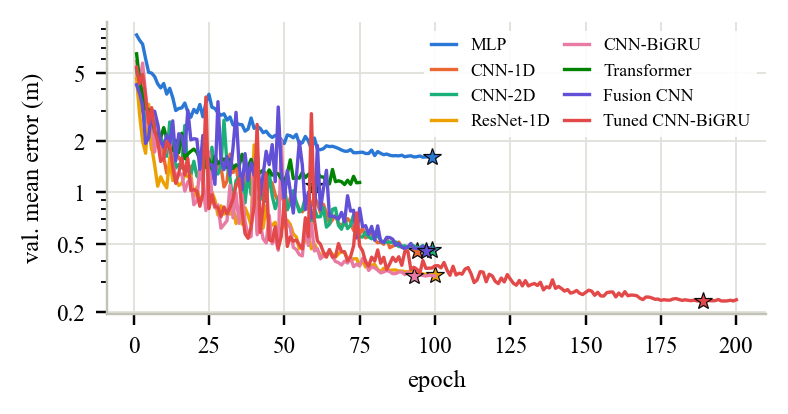

In [53]:
# Figure: report - learning curves
CURVES = ['MLP', 'CNN-1D', 'CNN-2D', 'ResNet-1D', 'CNN-BiGRU', 'Transformer', 'Fusion CNN', tuned_name]
with plt.rc_context(REPORT_RC):
    fig, ax = plt.subplots(figsize=(COL, 1.75))
    for i, name in enumerate(CURVES):
        hist = ann_hist[name]
        ax.plot(hist['epoch'], hist['val_error_m'], color=PALETTE[i], lw=1.1, label=name)
        b = hist.attrs['best_epoch']
        ax.plot(b, hist.loc[b - 1, 'val_error_m'], marker='*', ms=6, color=PALETTE[i], markeredgecolor='#0b0b0b', markeredgewidth=0.4)
    log_axis(ax, 'y')
    ax.set(xlabel='epoch', ylabel='val. mean error (m)')
    ax.legend(ncol=2, fontsize=5.8, loc='upper right', handlelength=1.4, columnspacing=0.8, frameon=True, framealpha=0.9, edgecolor='none')
    plt.tight_layout(pad=0.3)
    plt.show()

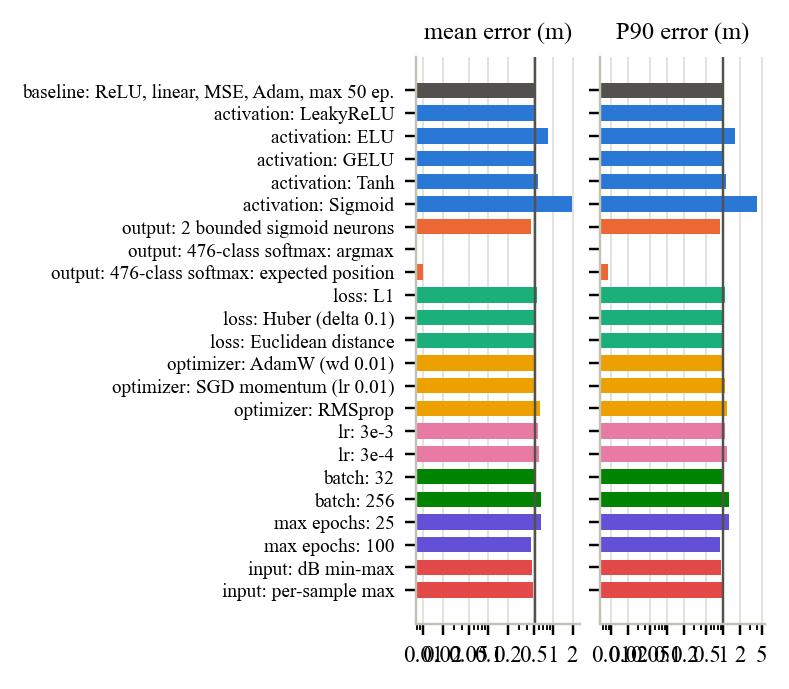

In [54]:
# Figure: report - configuration study
SHORT = {'Hidden activation': 'activation', 'Output layer': 'output', 'Loss function': 'loss', 'Optimizer': 'optimizer',
         'Learning rate': 'lr', 'Batch size': 'batch', 'Epoch budget': 'max epochs', 'Input normalization': 'input'}
rows = config_table[~config_table['setting'].str.endswith('(baseline)')]
rows = pd.concat([pd.DataFrame([{**baseline, 'study': 'baseline', 'setting': f'ReLU, linear, MSE, Adam, max {CFG_EPOCHS} ep.'}]), rows])
labels = ['baseline: ' + rows['setting'].iloc[0]] + [f'{SHORT[s]}: {t}' for s, t in zip(rows['study'][1:], rows['setting'][1:])]
colors = ['#52514e'] + [PALETTE[list(STUDIES).index(s)] for s in rows['study'][1:]]
with plt.rc_context(REPORT_RC):
    fig, axes = plt.subplots(1, 2, figsize=(COL, 3.0), sharey=True)
    ypos = np.arange(len(rows))[::-1]
    for ax, (col, title) in zip(axes, [('mean_m', 'mean error (m)'), ('p90_m', 'P90 error (m)')]):
        ax.barh(ypos, rows[col], color=colors, height=0.68)
        ax.axvline(baseline[col], color='#52514e', lw=0.8)
        log_axis(ax)
        ax.set(title=title, yticks=ypos, yticklabels=labels)
        ax.grid(axis='y', visible=False)
        ax.tick_params(axis='y', labelsize=6.3)
    plt.tight_layout(pad=0.3, w_pad=0.4)
    plt.show()

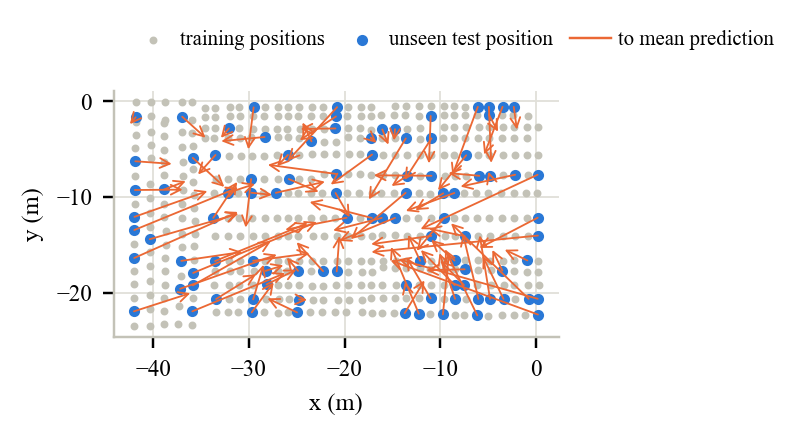

In [55]:
# Figure: report - unseen positions
per_pos = pd.DataFrame({'x': xy_unseen[:, 0], 'y': xy_unseen[:, 1], 'px': unseen_pred[best_unseen][:, 0],
                        'py': unseen_pred[best_unseen][:, 1]}).groupby(['x', 'y']).mean().reset_index()
with plt.rc_context(REPORT_RC):
    fig, ax = plt.subplots(figsize=(COL, 1.95))
    ax.scatter(seen_positions[:, 0], seen_positions[:, 1], s=2.5, color='#c3c2b7', label='training positions')
    ax.scatter(per_pos['x'], per_pos['y'], s=7, color=PALETTE[0], label='unseen test position', zorder=3)
    for _, r in per_pos.iterrows():
        ax.annotate('', xy=(r['px'], r['py']), xytext=(r['x'], r['y']),
                    arrowprops=dict(arrowstyle='->', color=PALETTE[1], lw=0.6, shrinkA=0, shrinkB=0))
    ax.plot([], [], color=PALETTE[1], lw=0.8, label='to mean prediction')
    ax.set(xlabel='x (m)', ylabel='y (m)')
    ax.set_aspect('equal')
    ax.legend(loc='upper left', bbox_to_anchor=(0, 1.32), ncol=3, columnspacing=0.8, handletextpad=0.3)
    plt.tight_layout(pad=0.3)
    plt.show()

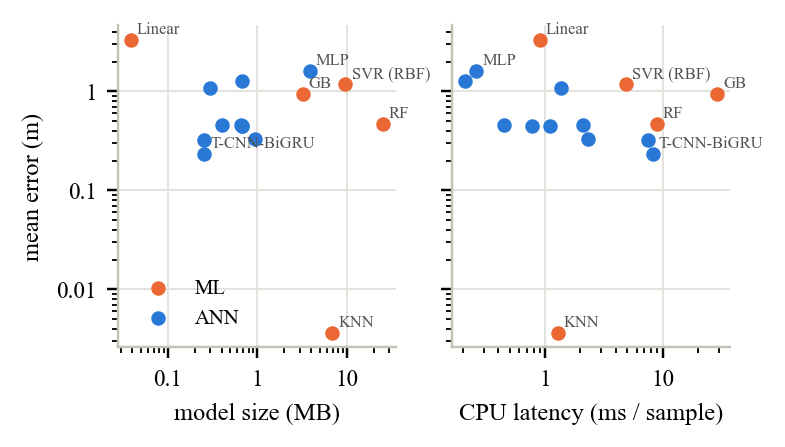

In [56]:
# Figure: report - accuracy vs cost
LABELED = list(final_ml) + ['MLP', tuned_name]
with plt.rc_context(REPORT_RC):
    fig, axes = plt.subplots(1, 2, figsize=(COL, 1.9), sharey=True)
    for ax, (col, xlabel) in zip(axes, [('size_MB', 'model size (MB)'), ('cpu_latency_ms', 'CPU latency (ms / sample)')]):
        for kind in ['ML', 'ANN']:
            s = summary[summary['type'] == kind]
            ax.scatter(s[col], s['mean_m'].clip(lower=1e-3), s=14, color=COLORS[kind], label=kind, zorder=3)
        for name in LABELED:
            short = name.replace('Linear Regression', 'Linear').replace('Gradient Boosting', 'GB').replace(
                'Random Forest', 'RF').replace('Multi-task CNN-1D', 'MTL').replace('Transformer', 'TF').replace('Tuned ', 'T-')
            ax.annotate(short, (summary.loc[name, col], max(summary.loc[name, 'mean_m'], 1e-3)), fontsize=5.4,
                        xytext=(2, 2), textcoords='offset points', color='#52514e')
        log_axis(ax, subs=(1,))
        log_axis(ax, 'y', subs=(1,))
        ax.set(xlabel=xlabel)
    axes[0].set_ylabel('mean error (m)')
    axes[0].legend(loc='lower left')
    plt.tight_layout(pad=0.3, w_pad=0.4)
    plt.show()

## 12. Conclusions

1. **Input design.** The received power alone is a poor distance estimator in the garage (Section 2); the full amplitude
   image (PCA features) is the best ML input, and the networks learn directly from the normalized CSI.
2. **Known positions (official validation set).** KNN fingerprinting is almost exact
   (0.0037 m) because every validation position is in the training set; the best ANN is
   Tuned CNN-BiGRU (0.232 m, best checkpoint at epoch 189 of at most
   200) and linear regression the worst (3.32 m).
3. **Configurations.** The output layer matters most: a 476-class softmax over the reference positions behaves like a
   fingerprint database (0.000 m with the arg-max); sigmoid hidden units are the worst activation
   (1.977 m); a longer schedule helps (0.645 m for at most 25 epochs, 0.530 m for at most 50 epochs, 0.460 m for at most 100 epochs); the other choices change the error much less (Section 6.2).
4. **Efficiency.** The kernel SVR is the slowest model to train (101 s); Random Forest is the
   largest (25.5 MB); CNNs are small (at most 0.94 MB) with single-sample CPU
   latencies of at most 2.30 ms; one multi-task CNN
   serves both tasks (Section 7.1).
5. **Unreliable network.** Noise and lost packets increase the errors of clean-trained models; repair and augmentation
   reduce the damage (Section 8).
6. **Unseen positions.** The best mean error is 5.46 m (ResNet-1D) against 0.0037 m on
   known positions: the models recognize fingerprints of known positions but do not interpolate between them (Section 9).
7. **Limitations.** The validation set shares its positions with the training set and is also used for model selection
   and early stopping, so its scores are optimistic; the unseen-position test is a single split with one seed.
